Step 1: Split the received signal as ref signal \& loc signal. Get the basic information including sample rate, starting time, etc, and save it to folder with name $date/

In [29]:
from utils.calibration import CalibrationSignal
from utils.imu_data import IMUData
import os
from matplotlib import pyplot as plt
import scipy.io as sio
import numpy as np
import time
# iq0_path = '/home/ishani/LeoPNT/USRP_data/3_12/utctime_12Mar2024_23_17_14_freq_11_325G_bw_2.0M_ts_1710285434.4520473_inrx0.dat'
# iq0_path = '/home/ishani/LeoPNT/USRP_data/3_12/utctime_12Mar2024_23_35_44_freq_11_325G_bw_2.0M_ts_1710286544.4498281_inrx0.dat'
# iq0_path = '/home/ishani/LeoPNT/USRP_data/3_12/utctime_13Mar2024_00_35_58_freq_11_325G_bw_2.0M_ts_1710290158.7682009_inrx0.dat'
# iq0_path = '/home/ishani/LeoPNT/USRP_data/3_12/utctime_13Mar2024_00_54_22_freq_11_325G_bw_2.0M_ts_1710291262.7842135_inrx0.dat'
# iq0_path = '/home/ishani/LeoPNT/USRP_data/3_12/utctime_13Mar2024_02_20_20_freq_11_325G_bw_2.0M_ts_1710296420.6706645_inrx0.dat'
# iq0_path = '/home/ishani/LeoPNT/USRP_data/3_12/utctime_13Mar2024_03_17_04_freq_11_325G_bw_2.0M_ts_1710299824.358615_inrx0.dat'
# iq0_path = '/home/ishani/LeoPNT/USRP_data/3_12/utctime_13Mar2024_03_59_01_freq_11_325G_bw_2.0M_ts_1710302341.7380192_inrx0.dat'
# iq0_path = '/home/ishani/LeoPNT/USRP_data/3_12/utctime_13Mar2024_05_37_23_freq_11_325G_bw_2.0M_ts_1710308243.820163_inrx0.dat'
# iq0_path = '/home/ishani/LeoPNT/USRP_data/3_5/utctime_6Mar2024_03_51_14_freq_11_325G_bw_2.0M_ts_1709697074.3228533_inrx0.dat'
iq0_path = '/home/ishani/LeoPNT/synthetic_data/python/recorded_signal_2024-06-30_06-00-00_rx0.dat'
# iq0_path = '/home/ishani/LeoPNT/USRP_data/2_20/utctime_20Feb2024_23_19_57_freq_11_325G_bw_2.0M_ts_1708471197.0514207_inrx0.dat'
# iq0_path = 'aa'
# imu_path = '/home/ishani/LeoPNT/USRP_data/3_12/imu_utctime_2024_03_12_23_16_53.txt'
# imu_path = '/home/ishani/LeoPNT/USRP_data/3_12/imu_utctime_2024_03_12_23_35_25.txt'
# imu_path = '/home/ishani/LeoPNT/USRP_data/3_12/imu_utctime_2024_03_13_00_35_37.txt'
# imu_path = '/home/ishani/LeoPNT/USRP_data/3_12/imu_utctime_2024_03_13_00_54_03.txt'
# imu_path = '/home/ishani/LeoPNT/USRP_data/3_12/imu_utctime_2024_03_13_02_20_00.txt'
# imu_path = '/home/ishani/LeoPNT/USRP_data/3_12/imu_utctime_2024_03_13_03_16_43.txt'
# imu_path = '/home/ishani/LeoPNT/USRP_data/3_12/imu_utctime_2024_03_13_03_58_41.txt'
# imu_path = '/home/ishani/LeoPNT/USRP_data/3_12/imu_utctime_2024_03_13_05_37_03.txt'
# imu_path = '/home/ishani/LeoPNT/USRP_data/3_5/imu_utctime_2024_03_06_03_50_54.txt'
imu_path = '/home/ishani/LeoPNT/USRP_data/3_5/imu_utctime_2024_03_06_04_19_12.txt'
# imu_path = '/home/ishani/LeoPNT/USRP_data/2_20/imu_utctime_2024_02_20_23_19_38.txt'
# imu_path = '/home/ishani/LeoPNT/USRP_data/2_5/imu_20240205235759.txt'
iq1_path = iq0_path.replace('rx0', 'rx1')
iq2_path = iq0_path.replace('rx0', 'rx2')
# date = iq0_path.split('_')[-12]+'_'+iq0_path.split('_')[-11]+'_'+iq0_path.split('_')[-10]
start_time = 1719727200.0 
# TODO: add delay to the start time to generate results for effect of satellite position on the localization  
start_time = start_time
# from timestanp to utc time
print(time.strftime('%Y-%m-%d %H:%M:%S', time.gmtime(start_time)))
date = '30Jun2024_06_00_00'
# start_time = 1707177488.0938272
fc = 11.325e9
tx_freq = 11.3251e9
sample_rate = 2e6
d, lam = 13.25e-2, 299792458 / fc
imu = IMUData(imu_path)
imu_data = imu.read_imu_data()
lat, lon, alt = imu.get_latlonalt_()
lat_gt, lon_gt, alt_gt = np.mean(lat), np.mean(lon), np.mean(alt)
orient = imu.get_attitude()
lat_gt, lon_gt = (40.11389690596162, -88.22484814695467) 
yaw, pitch, roll = np.mean(orient[2][-3000:-1]), np.mean(orient[1]), np.mean(orient[0])
print('ground truth lat, lon, alt: ', lat_gt, lon_gt, alt_gt)
print(date)
# print('Calibrating the phase offsets between the three USRPs...')
# cal0 = CalibrationSignal(iq0_path, fc, tx_freq, sample_rate) # creates an instance of CalibrationSignal. More details in utils/calibration.py 
# cal1 = CalibrationSignal(iq1_path, fc, tx_freq, sample_rate)
# cal2 = CalibrationSignal(iq2_path, fc, tx_freq, sample_rate)
# ref_sig_idx = cal0.get_all_refsigidx() # use the get_all_refsigidx() method to get the start and stop index of the reference signal
# phase_0 = cal0.get_refsig_phase(ref_sig_idx)
# phase_1 = cal1.get_refsig_phase(ref_sig_idx)
# phase_2 = cal2.get_refsig_phase(ref_sig_idx)
ref_sig_idx = 0
phase_0 = np.zeros(10)
phase_1 = np.zeros(10)
phase_2 = np.zeros(10)

t_end = 600  # use the stop time of the last ref sig as the duration of the file
phase_offset_01 = np.unwrap(phase_0-phase_1)
phase_offset_21 = np.unwrap(phase_2-phase_1)

date = date + '_synthetic'
if not os.path.exists(date):
    os.makedirs(date)
# save sample_rate, date, start_time, loc_sig_idx to .mat file
sio.savemat(date + '/info.mat', {'IQ_Sample_file_0': iq0_path,'sample_rate': sample_rate, 'date': date, 'start_time': start_time, 'ref_sig_idx': ref_sig_idx, 't_end': t_end, 'phase_offset_01': phase_offset_01, 'phase_offset_21': phase_offset_21, 'lat_gt': lat_gt, 'lon_gt': lon_gt, 'alt_gt': alt_gt})
# print('Calibration done, results saved in ' + date + '/info.mat')
# plt.figure(10)
# plt.clf()
# plt.plot(phase_offset_01, label='rx0    -    rx1')
# plt.plot(phase_offset_21, label='rx2    -    rx1')
# plt.xlabel('ref sig #')
# plt.legend(loc='upper right')
# plt.show()
# print(t_end)

2024-06-30 06:00:00
ground truth lat, lon, alt:  40.11389690596162 -88.22484814695467 191.86824283954982
30Jun2024_06_00_00


Step 2: do the central tone tracking using matlab

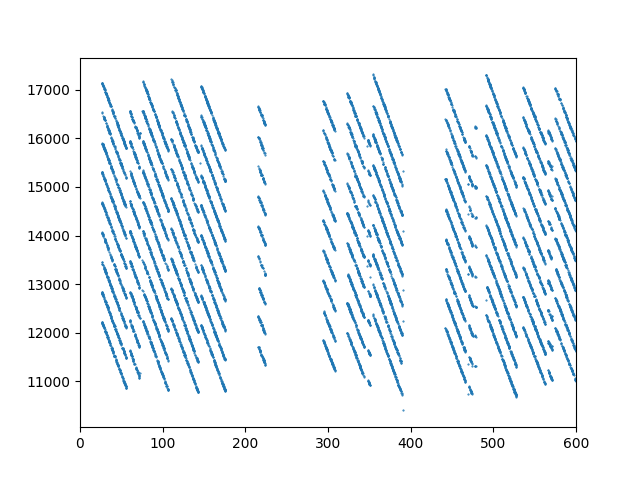

In [30]:
# need to change date first in matlab file
# matlab
# cd Starloc/
# phase_from_bin_track
# results saved to $date/res.mat
# have a look at the results
from matplotlib import pyplot as plt
from scipy import io as sio
%matplotlib widget
res = sio.loadmat(date + '/res.mat')['res']
plt.figure(1)
plt.clf()
plt.plot(res[:, 0].real, res[:, 1].real, '.', markersize=1)
plt.xlim(0, t_end)
plt.show()

Step 3: simulate doppler, first need to move the tle file to the date folder with name `Starlink.tle`

THIS STEP CAN BE SKIPPED IF USING BLIND ID IDENTIFICATION

In [3]:
from sat_id import connect_doppler, doppler_sim, faster_doppler_sim
sim_start_time = start_time
t_end = sio.loadmat(date + '/info.mat')['t_end'][0][0]
lat_gt, lon_gt = sio.loadmat(date + '/info.mat')['lat_gt'][0][0], sio.loadmat(date + '/info.mat')['lon_gt'][0][0]
print('lat_gt, lon_gt: ', lat_gt, lon_gt)
sim_end_time = sim_start_time+t_end
# sat_dopp_dict, t_list = doppler_sim(date, date+'/Starlink.tle', fc, sim_start_time, sim_end_time, 1)
sat_dopp_dict, t_list = faster_doppler_sim(date, date+'/Starlink.tle', fc, sim_start_time, sim_end_time, 1, ground_station=(lat_gt, lon_gt))
output_doppler_file = date+"/output_doppler.mat"
output = {}
sio.savemat(output_doppler_file, {'sat_dopp_dict': sat_dopp_dict, 't_list': t_list})

lat_gt, lon_gt:  40.11389690596162 -88.22484814695467
number of Starlink satellites loaded 6179
Duration in secs:  600.0


KeyboardInterrupt: 

Step 4: Run `phase_from_bin.m` to get phase difference. Also find the time-stamp of each satellite passing the max elevation for blind id

30Jun2024_06_00_00_synthetic


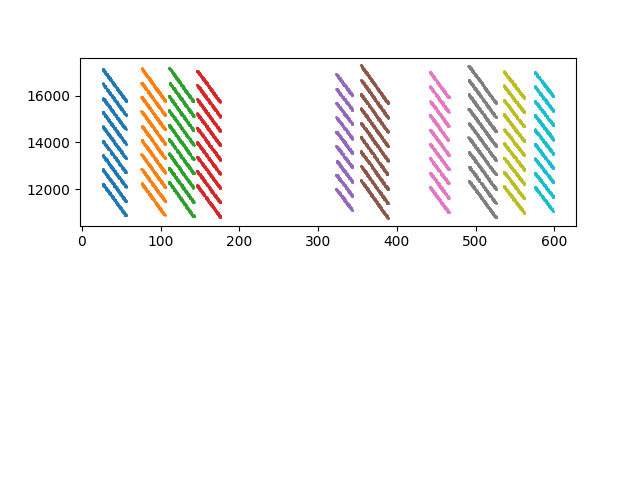

In [31]:
# t_sim_list = sio.loadmat(date+'/output_doppler.mat')['t_list']
print(date)
dopp_track_dict = sio.loadmat(date+'/phase_comp.mat')['dopp_track_dict']
dopp_track_main_dict = sio.loadmat(date+'/doppler_track.mat')['dopp_track_main_dict']
id_dict = sio.loadmat(date+'/phase_comp.mat')['id_dict']
sat_dopp_struct = sio.loadmat(date+'/phase_comp.mat')['sat_dopp_dict']
ref_sig_idx = sio.loadmat(date+'/info.mat')['ref_sig_idx']
phase_offset_01 = sio.loadmat(date+'/info.mat')['phase_offset_01'][0]
phase_offset_21 = sio.loadmat(date+'/info.mat')['phase_offset_21'][0]
sat_num = len(dopp_track_dict[0, :])
time_arr, is_middle_arr, dopp_coeff_list = [], [], []
pw_list_0, pw_list_1, pw_list_2 = [], [], []
plt.figure(2)
plt.clf()
plt.subplot(2,1,1)
for sat_idx in range(sat_num):
    dopp_track = dopp_track_dict[0, sat_idx]
    t_repeat = dopp_track[:, 0].real
    dopp_repeat = dopp_track[:, 1].real
    plt.plot(t_repeat, dopp_repeat, '.', label=id_dict[0, sat_idx][0], markersize=2)
plt.show()
plt.ylabel('doppler bin')
# plt.legend(fontsize='x-small', loc='upper right')
plt.subplot(2,1,2)
for sat_idx in range(sat_num):
    dopp_track = dopp_track_main_dict[0, sat_idx]
    t_repeat = dopp_track[:, 0].real
    dopp_repeat = dopp_track[:, 1].real
    t_sat_start, t_sat_end = np.min(t_repeat), np.max(t_repeat)
    p = np.polyfit(t_repeat, dopp_repeat, 3, w=np.abs(dopp_track[:, 2])**2)
    t = np.arange(t_sat_start, t_sat_end, 0.001)
    dopp = np.polyval(p, t)
    dopp_diff = np.diff(dopp) / np.diff(t)
    t_diff = t[0:-1] + 0.001 / 2
    # find the min value of the derivative
    min_idx = np.argmin(dopp_diff)
    time_arr.append(t_diff[min_idx])
    dopp_coeff_list.append(p)
    pw_list_0.append(np.mean(np.abs(dopp_track[:, 2])**2))
    pw_list_1.append(np.mean(np.abs(dopp_track[:, 3])**2))
    pw_list_2.append(np.mean(np.abs(dopp_track[:, 4])**2))
    is_middle_arr.append(min_idx != 0 and min_idx != len(dopp_diff)-1)
    plt.plot(t_diff, dopp_diff, label=id_dict[0, sat_idx][0], markersize=2)
    plt.scatter(t_diff[min_idx], dopp_diff[min_idx])
plt.ylabel('doppler rate (Hz/s)')
plt.xlabel('time (s)')
is_middle_arr = np.array(is_middle_arr)

Step 5: Blind ID

30Jun2024_06_00_00_synthetic
start_time_datetime:  2024-06-30 06:00:00.040000+00:00
time_arr:  [42.00250050001931, 91.1815005000745, 126.30350050007235, 158.05150050005744, 333.4955004997532, 371.1895004998232, 454.3395004997081, 515.3525004997751, 549.1345004996792, 588.3605004996845]


/home/ishani/LeoPNT/starlink_ofdm/Starloc/utils/satid_blind_identification.py:179: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))


Initial number of candidate location clusters: 11469
Possible: 97
Centroid of group  0 : [ 33.06306812 -89.92952225]
sats in group: ['STARLINK-1760', 'STARLINK-30571', 'STARLINK-5419', 'STARLINK-3594', 'STARLINK-5416', 'STARLINK-30506', 'STARLINK-3579', 'STARLINK-30315', 'STARLINK-31680', 'STARLINK-3256']
Centroid of group  1 : [ 33.07485643 -89.97347719]
sats in group: ['STARLINK-31370', 'STARLINK-30571', 'STARLINK-5419', 'STARLINK-3594', 'STARLINK-5416', 'STARLINK-30506', 'STARLINK-3579', 'STARLINK-30315', 'STARLINK-31680', 'STARLINK-3256']
Centroid of group  2 : [ 32.99184929 -90.01993292]
sats in group: ['STARLINK-1760', 'STARLINK-30571', 'STARLINK-5419', 'STARLINK-31624', 'STARLINK-5416', 'STARLINK-30506', 'STARLINK-3579', 'STARLINK-30315', 'STARLINK-31680', 'STARLINK-3256']
Centroid of group  3 : [ 33.00673699 -90.05163464]
sats in group: ['STARLINK-31370', 'STARLINK-30571', 'STARLINK-5419', 'STARLINK-31624', 'STARLINK-5416', 'STARLINK-30506', 'STARLINK-3579', 'STARLINK-30315', '

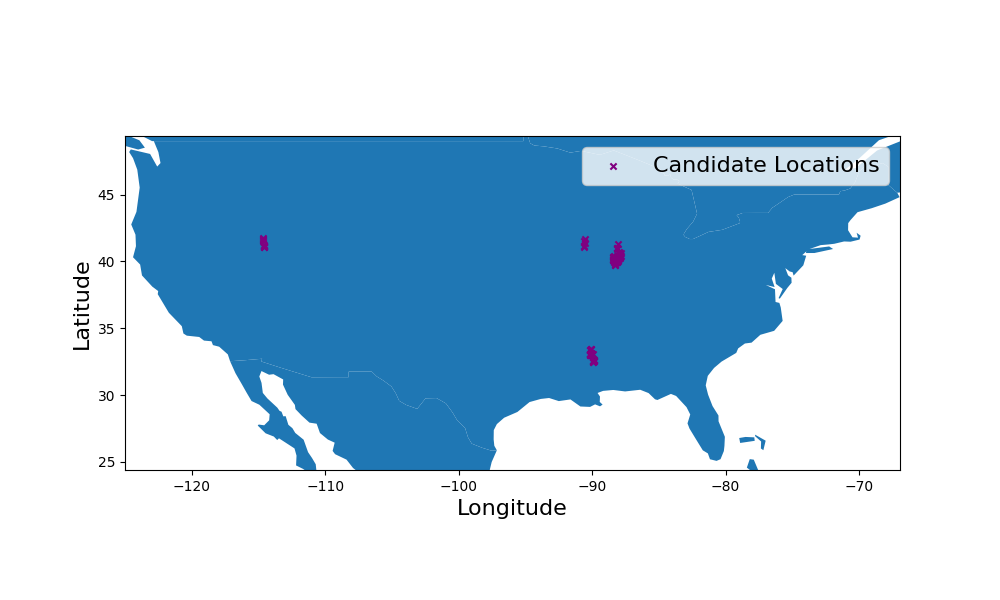

In [32]:
from datetime import datetime
import pytz
# date = os.path.join('/home/ishani/LeoPNT/starlink_ofdm/Starloc/results/final', date)
print(date)
start_time_datetime = datetime.fromtimestamp(start_time, tz=pytz.utc)
print('start_time_datetime: ', start_time_datetime)
tle_path = date+'/Starlink.tle'
mat = sio.loadmat(date+'/phase_comp.mat')
tracked_peaks = mat['dopp_track_dict'][0]
# sort time_arr
# time_arr = sorted(time_arr)
print('time_arr: ', time_arr)
time_arr = np.array(time_arr)
%matplotlib widget
# plt.figure(3)
# plt.clf()
fig, ax = plt.subplots(1,1,figsize=(10,6))
# call get_candidate_locs
from utils.satid_blind_identification import get_candidate_locs, get_candidate_locs_jida
search_radius = 220 # in km
gs_groups, coarse_gs, sat_groups = get_candidate_locs_jida(start_time_datetime, time_arr, is_middle_arr, tle_path, search_dist_bound=search_radius, fig_pointer=(fig, ax))
# plot the ground truth location
# get gt location from imu file
from utils.imu_data import IMUData
imu_data = IMUData(imu_path)
lat_lon_alt = imu_data.get_latlonalt()
# average out the lat lon alt
lat_lon_alt_mean = np.mean(lat_lon_alt, axis=0)
# ax.scatter(lat_lon_alt_mean[1], lat_lon_alt_mean[0], c='red', marker='*',s=30, label='True Location')
ax.legend(fontsize=16)
# ax.scatter(-88.20952606201173, 40.07216262817384, c='red', marker='*',s=15)
ax.set_xlabel('Longitude', fontsize=16)
ax.set_ylabel('Latitude', fontsize=16)
# ax.set_title('Candidate Ground Station Locations')
plt.savefig(date+'/candidate_gs.pdf')
plt.show()

phase diff to exclude impossible sats, doppler to uniquely determine the id

In [33]:
from sat_id import get_phase_diff_params_allsatsingroups_jida, calc_doppler_blind_id
from utils.helper import get_distkm_latlon_coordinates
from tqdm import tqdm
slope_mes = sio.loadmat(date+'/doppler_track.mat')['slope_mes']
phase_slope = get_phase_diff_params_allsatsingroups_jida(gs_groups, coarse_gs, sat_groups, time_arr+start_time, date+'/Starlink.tle', 0, pitch, roll, d, lam)
phase_slope = np.array(phase_slope)

err = np.array([])
max_phase_err_pergs = [[] for i in range(len(gs_groups))]
refined_candidates = []
remove_candidates = []
for i in (range(len(gs_groups))):
    sat_group_i = sat_groups[i]
    coarse_gs_i = coarse_gs[i]
    phase_slope_i = phase_slope[i]
    err_i = 0
    for j in range(len(sat_group_i)):

        # exclude based on phase slope
        if np.max(np.abs(phase_slope_i[j] - slope_mes[j])) > 0.1:
            err_i = np.inf
            max_phase_err_pergs[i] = np.max(np.abs(phase_slope_i[j] - slope_mes[j]))
            if i in refined_candidates:
                remove_candidates.append(i)
            break
        else:
            max_phase_err_pergs[i] = np.max(np.abs(phase_slope_i[j] - slope_mes[j]))
            refined_candidates.append(i)

        sat_ij = sat_group_i[j]
        dopp_coeff = dopp_coeff_list[j]
        dopp_track = dopp_track_main_dict[0, j]
        t_repeat = dopp_track[:, 0].real
        dopp_repeat = dopp_track[:, 1].real
        t_sat_start, t_sat_end = np.min(t_repeat), np.max(t_repeat)
        #TODO: min ele set to 75 for synthetic data
        _, t_dopp_sim, dopp_sim, _, _, _ = calc_doppler_blind_id(sat_ij, coarse_gs_i, t_sat_start+start_time, t_sat_end+start_time, 10)
        t_dopp_sim += t_sat_start
        dopp_mes = np.polyval(dopp_coeff, t_dopp_sim)
        err_i += np.var(dopp_mes-dopp_sim)
    err = np.append(err, err_i)
print('Coarse GS: ', coarse_gs[np.argmin(err)], np.argmin(err))
coarse_gs_lat, coarse_gs_lon = coarse_gs[np.argmin(err)]
print('Coarse location error in kilometers :', get_distkm_latlon_coordinates([lat_gt, lon_gt], [coarse_gs_lat, coarse_gs_lon]))
for j in range(len(sat_group_i)):
    print(id_dict[0][j][0] + ': ', sat_groups[np.argmin(err)][j].name == id_dict[0][j][0])
sio.savemat(date+'/blind_id.mat', {'coarse_lat': coarse_gs_lat, 'coarse_lon': coarse_gs_lon})


100%|██████████| 97/97 [00:04<00:00, 22.60it/s]


Coarse GS:  [ 40.10735734 -88.09294805] 41
Coarse location error in kilometers : [11.24060443]
STARLINK-2396:  True
STARLINK-3632:  True
STARLINK-3296:  True
STARLINK-2612:  True
STARLINK-5196:  True
STARLINK-4768:  True
STARLINK-2409:  True
STARLINK-2526:  True
STARLINK-5964:  True
STARLINK-30922:  True


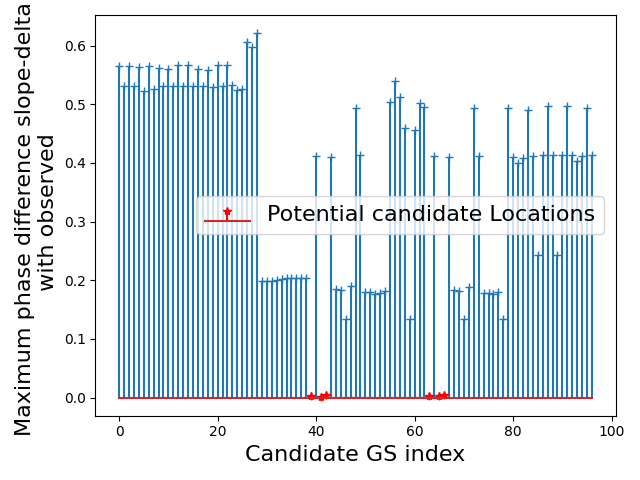

In [34]:
# plot max_phase_err_pergs
# if a number is in remove_candidates, remove it from refined_candidates
refined_candidates = list(set(refined_candidates) - set(remove_candidates))
plt.figure()
plt.stem(range(len(coarse_gs)), max_phase_err_pergs, markerfmt='+')
plt.stem(refined_candidates, np.array(max_phase_err_pergs)[refined_candidates], markerfmt='*', linefmt='r', label='Potential candidate Locations')
plt.xlabel('Candidate GS index', fontsize=16)
plt.ylabel('Maximum phase difference slope-delta \n with observed', fontsize=16)
plt.legend(fontsize=16)
plt.tight_layout()
plt.savefig(date+'/max_phase_err_pergs.pdf')
# plt.stem(best_candidate_idx, np.sum(min_param_diff_pertime_each_gs, axis=1)[best_candidate_idx],markerfmt='*', linefmt='r', label='Best candidate loc\n'+str(best_coarse_gs_candidate))
# plt.xlabel('Candidate GS index')
# plt.ylabel('Minimum phase difference slope-delta with observed')
# plt.legend()
# plt.show()

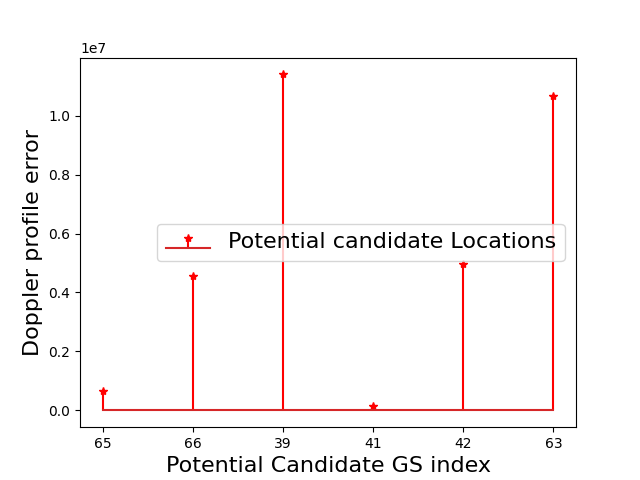

In [35]:
# plot doppler errors now
plt.figure()
x = list(range(len(refined_candidates)))
plt.stem(x, err[refined_candidates], markerfmt='*', linefmt='r', label='Potential candidate Locations')
# plt.stem(x[1], err[102], markerfmt='*', linefmt='g', label='Chosen Candidate Location')
# set x ticks
plt.xticks(x, [str(i) for i in refined_candidates])
plt.xlabel('Potential Candidate GS index', fontsize=16)
plt.ylabel('Doppler profile error', fontsize=16)
plt.legend(fontsize=16)
plt.savefig(date+'/doppler_profile_err.pdf')

Step 6: Do localization based on phase diff (this part is moved to `recover_orientation.ipynb`)

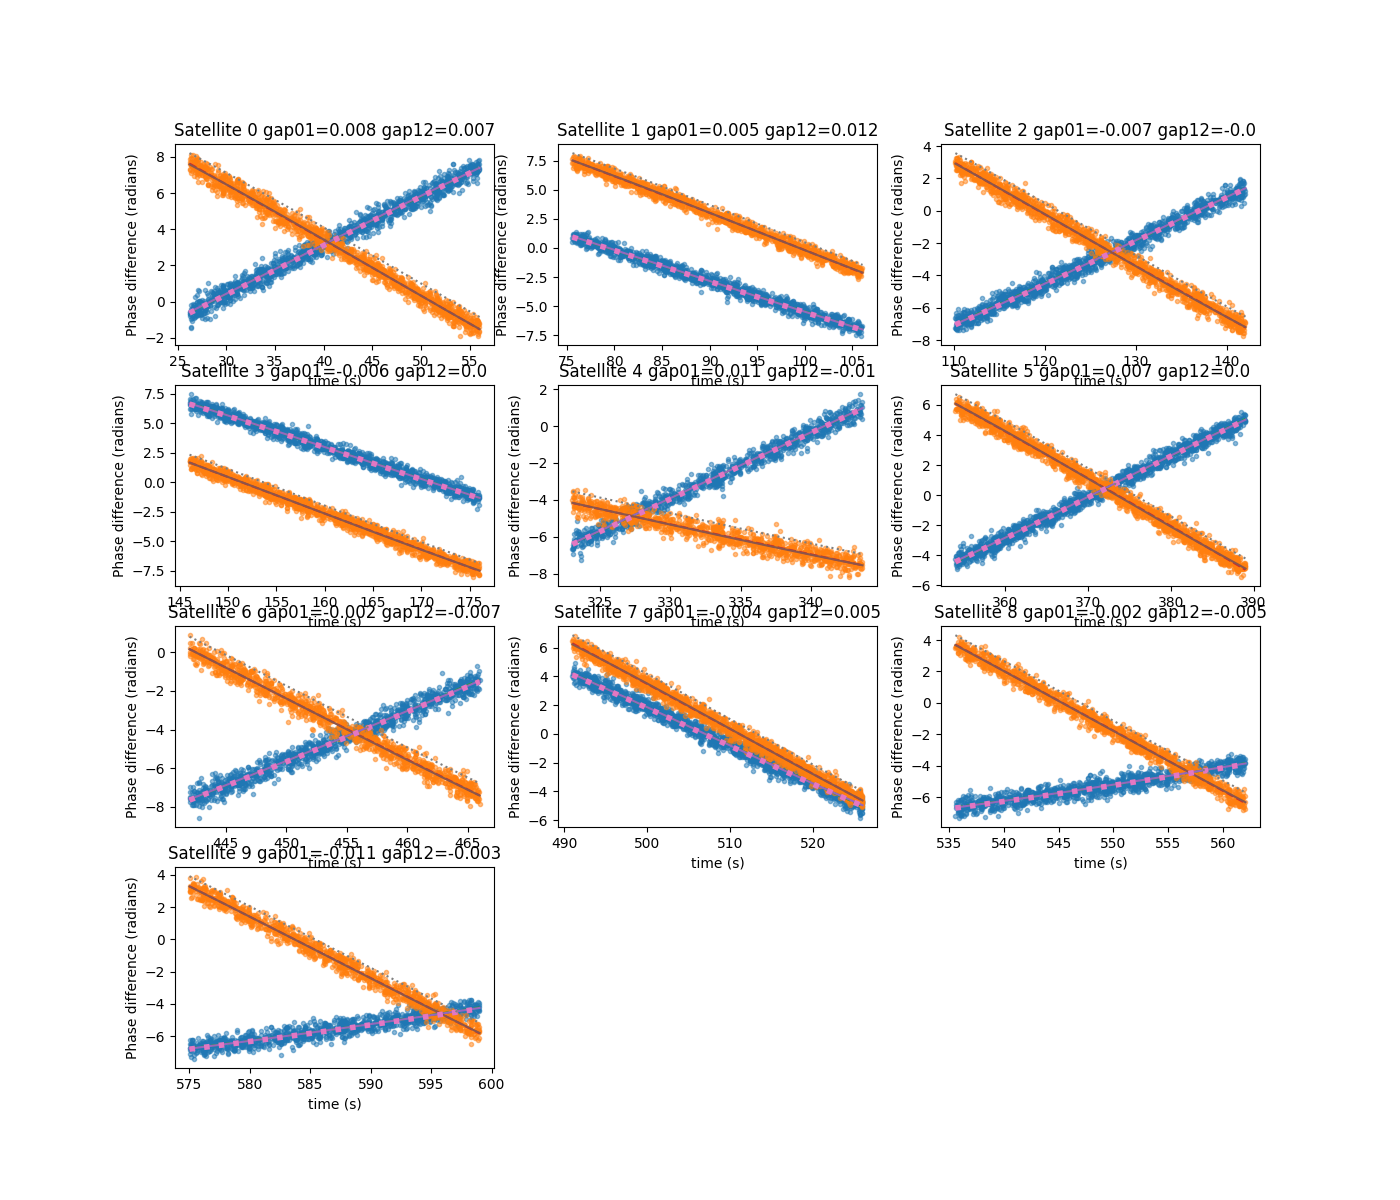

In [20]:
from sat_id import aoa_sim_1_sat_loc

plt.figure(figsize=(14,12))
# Rx antenna locations
rx_loc_1, rx_loc_0, rx_loc_2 = np.array([0,0,0]), np.array([0,-d,0]), np.array([d,0,0])
gap_01_arr, gap_12_arr = np.array([]), np.array([]) # one gap for each satellite
az_gt_list, el_gt_list, range_gt_list, az_coarse_list, el_coarse_list, range_coarse_list, timestamps_list = [], [], [], [], [], [], [] # each list has one entry for each satellite
sat_loc_gt_list, sat_loc_coarse_list = [], [] # each list has one entry for each satellite
del_phi_01_polyfit_list, del_phi_12_polyfit_list = [], []

for sat_idx in range(sat_num):
    sat_dopp_track = dopp_track_dict[0, sat_idx]
    t = sat_dopp_track[:, 0].real
    t_sat_start, t_sat_end = np.min(t), np.max(t)
    phi0_alltones = np.angle(sat_dopp_track[:, 2])
    phi1_alltones = np.angle(sat_dopp_track[:, 3])
    phi2_alltones = np.angle(sat_dopp_track[:, 4])
    del_phi_01_alltones = np.unwrap(phi0_alltones-phi1_alltones)
    del_phi_12_alltones = np.unwrap(phi1_alltones-phi2_alltones)

    p_del_phi_01 = np.polyfit(t, del_phi_01_alltones, 2, w = np.minimum(np.abs(sat_dopp_track[:, 2]), np.abs(sat_dopp_track[:, 3])))
    p_del_phi_12 = np.polyfit(t, del_phi_12_alltones, 2, w = np.minimum(np.abs(sat_dopp_track[:, 3]), np.abs(sat_dopp_track[:, 4])))

    """ TODO: Test this part
    # # now get del_phi_01 variance of all points
    # sigma_del_phi_01 = np.std(del_phi_01_alltones - np.polyval(p_del_phi_01, t))
    # sigma_del_phi_12 = np.std(del_phi_12_alltones - np.polyval(p_del_phi_12, t))

    # # refit the polynomial with the weights
    # p_del_phi_01 = np.polyfit(t, del_phi_01_alltones, 2, w = np.minimum(np.abs(sat_dopp_track[:, 2]), np.abs(sat_dopp_track[:, 3]))/sigma_del_phi_01)
    # p_del_phi_12 = np.polyfit(t, del_phi_12_alltones, 2, w = np.minimum(np.abs(sat_dopp_track[:, 3]), np.abs(sat_dopp_track[:, 4]))/sigma_del_phi_12)
    """

    # 1. get the gt del_phi_01 and del_phi_12 using gt location and TLE 
    t_sim, az_gt, el_gt, range_gt, sat_loc_gt = aoa_sim_1_sat_loc(date, date+'/Starlink.tle', id_dict[0,sat_idx][0], start_time+t_sat_start, start_time+t_sat_end, .1, lat_gt, lon_gt, alt_gt)
    timestamps = t_sim+t_sat_start
    az_gt, el_gt = np.deg2rad(az_gt), np.deg2rad(el_gt)
    az_gt_list.append(az_gt)
    el_gt_list.append(el_gt)
    range_gt_list.append(range_gt)
    sat_loc_gt_list.append(sat_loc_gt)
    timestamps_list.append(timestamps)
    # 2. consider the gt location as origin and get the location of sat     
    loc_sat_wrt_gt = np.array([range_gt*np.cos(el_gt)*np.sin(az_gt), range_gt*np.cos(el_gt)*np.cos(az_gt), range_gt*np.sin(el_gt)]).T
    
    # repeat the above two steps for coarse gt location and TLE
    _, az_coarse, el_coarse, range_coarse, sat_loc_coarse = aoa_sim_1_sat_loc(date, date+'/Starlink.tle', id_dict[0,sat_idx][0], start_time+t_sat_start, start_time+t_sat_end, .1, coarse_gs_lat, coarse_gs_lon)
    az_coarse, el_coarse = np.deg2rad(az_coarse), np.deg2rad(el_coarse)
    loc_sat_wrt_coarse_gt = np.array([range_coarse*np.cos(el_coarse)*np.sin(az_coarse), range_coarse*np.cos(el_coarse)*np.cos(az_coarse), range_coarse* np.sin(el_coarse)]).T
    az_coarse_list.append(az_coarse)
    el_coarse_list.append(el_coarse)
    range_coarse_list.append(range_coarse)
    sat_loc_coarse_list.append(sat_loc_coarse)
    
    # get phase difference between the rx antennas given the location of the satellite wrt gt location
    distance_bw_rx0_satloc_gt = np.linalg.norm(loc_sat_wrt_gt - rx_loc_0, axis=1)
    distance_bw_rx1_satloc_gt = np.linalg.norm(loc_sat_wrt_gt - rx_loc_1, axis=1)
    distance_bw_rx2_satloc_gt = np.linalg.norm(loc_sat_wrt_gt - rx_loc_2, axis=1)
    del_phi_01_gt = -2*np.pi*(distance_bw_rx0_satloc_gt - distance_bw_rx1_satloc_gt)/lam
    del_phi_12_gt = -2*np.pi*(distance_bw_rx1_satloc_gt - distance_bw_rx2_satloc_gt)/lam
    if np.any(distance_bw_rx0_satloc_gt > 1e6) or np.any(distance_bw_rx1_satloc_gt > 1e6) or np.any(distance_bw_rx2_satloc_gt > 1e6):
        print('Attention!! Distance between rx_gt and satellite location is too large')
        print('satellite index: ', sat_idx, id_dict[0,sat_idx][0], np.max(distance_bw_rx0_satloc_gt), np.max(distance_bw_rx1_satloc_gt), np.max(distance_bw_rx2_satloc_gt))

    # get phase difference between the rx antennas given the location of the satellite wrt coarse gt location
    distance_bw_rx0_satloc_coarse = np.linalg.norm(loc_sat_wrt_coarse_gt - rx_loc_0, axis=1)
    distance_bw_rx1_satloc_coarse = np.linalg.norm(loc_sat_wrt_coarse_gt - rx_loc_1, axis=1)
    distance_bw_rx2_satloc_coarse = np.linalg.norm(loc_sat_wrt_coarse_gt - rx_loc_2, axis=1)
    del_phi_01_coarse_gt = -2*np.pi*(distance_bw_rx0_satloc_coarse - distance_bw_rx1_satloc_coarse)/lam
    del_phi_12_coarse_gt = -2*np.pi*(distance_bw_rx1_satloc_coarse - distance_bw_rx2_satloc_coarse)/lam
    if np.any(distance_bw_rx0_satloc_coarse > 1e6) or np.any(distance_bw_rx1_satloc_coarse > 1e6) or np.any(distance_bw_rx2_satloc_coarse > 1e6):
        print('Attention!! Distance between rx_coarse and satellite location is too large')
        print('satellite index: ', sat_idx, id_dict[0,sat_idx][0], np.max(distance_bw_rx0_satloc_coarse), np.max(distance_bw_rx1_satloc_coarse), np.max(distance_bw_rx2_satloc_coarse))

    del_phi_01_fit = np.polyval(p_del_phi_01, timestamps)
    del_phi_12_fit = np.polyval(p_del_phi_12, timestamps)

    sig_del_phi_01 = np.abs(np.polyval(p_del_phi_01, t) - del_phi_01_alltones)
    sig_del_phi_12 = np.abs(np.polyval(p_del_phi_12, t) - del_phi_12_alltones)
    # first get rid of gap due to 2*pi jumps
    if np.abs(np.mean(del_phi_01_gt - del_phi_01_fit)) > 2*np.pi-np.max(sig_del_phi_01):
        rm_pi_gap_01 = 2*np.pi*np.round((np.mean(del_phi_01_gt - del_phi_01_fit))/(2*np.pi))
        del_phi_01_alltones += rm_pi_gap_01
    if np.abs(np.mean(del_phi_12_gt - del_phi_12_fit)) > 2*np.pi-np.max(sig_del_phi_12):
        rm_pi_gap_12 = 2*np.pi*np.round((np.mean(del_phi_12_gt - del_phi_12_fit))/(2*np.pi))
        del_phi_12_alltones += rm_pi_gap_12

    p_del_phi_01_refit = np.polyfit(t, del_phi_01_alltones, 2, w = np.minimum(np.abs(sat_dopp_track[:, 2]), np.abs(sat_dopp_track[:, 3]))/sig_del_phi_01)
    p_del_phi_12_refit = np.polyfit(t, del_phi_12_alltones, 2, w = np.minimum(np.abs(sat_dopp_track[:, 3]), np.abs(sat_dopp_track[:, 4]))/sig_del_phi_12)
    del_phi_01_polyfit_list.append(p_del_phi_01_refit)
    del_phi_12_polyfit_list.append(p_del_phi_12_refit)
    
    # Now get "gap" between del_phi_gt and del_phi_alltones
    gap_01 = np.mean(del_phi_01_gt - np.polyval(p_del_phi_01_refit, timestamps))
    gap_12 = np.mean(del_phi_12_gt - np.polyval(p_del_phi_12_refit, timestamps))
    gap_01_arr = np.append(gap_01_arr, gap_01)
    gap_12_arr = np.append(gap_12_arr, gap_12)
    
    plt.subplot(4,3,sat_idx+1)
    plt.plot(t, del_phi_01_alltones, '.', label='rx0 - rx1', alpha=0.5)
    plt.plot(t, del_phi_12_alltones, '.', label='rx1 - rx2', alpha=0.5)
    plt.plot(timestamps, np.polyval(p_del_phi_01_refit, timestamps), label='rx0 - rx1 fit', linestyle='--')
    plt.plot(timestamps, np.polyval(p_del_phi_12_refit, timestamps), label='rx1 - rx2 fit', linestyle='--')
    plt.plot(timestamps, del_phi_01_gt, label='rx0 - rx1 gt')
    plt.plot(timestamps, del_phi_12_gt, label='rx1 - rx2 gt')
    plt.plot(timestamps, del_phi_01_coarse_gt, label='rx0 - rx1 coarse gt', linestyle=':', linewidth=4)
    plt.plot(timestamps, del_phi_12_coarse_gt, label='rx1 - rx2 coarse gt', linestyle=':', )
    # plt.legend(fontsize=6, loc='upper right', ncol=2)
    plt.xlabel('time (s)')
    plt.ylabel('Phase difference (radians)')
    
for sat_idx in range(sat_num):
    # print('satellite index: ', sat_idx, 'gap01: ', str(round(gap_01_arr[sat_idx]-np.mean(gap_01_arr),3)), 'gap12: ', str(round(gap_12_arr[sat_idx]-np.mean(gap_12_arr),3)))
    # print(gap_01_arr[sat_idx], gap_12_arr[sat_idx], np.mean(gap_01_arr), np.mean(gap_12_arr))
    plt.subplot(4,3,sat_idx+1)
    plt.title('Satellite '+str(sat_idx)+' gap01='+str(round(gap_01_arr[sat_idx]-np.mean(gap_01_arr),3))+' gap12='+str(round(gap_12_arr[sat_idx]-np.mean(gap_12_arr),3)))



### Gradient Descent for localization

In [23]:
def SPP(num_sats, lat_c, lon_c, lat_gt, lon_gt, h, d, Rotation_mat, wave_len, t_dict, del_phi_01_fit, del_phi_12_fit, sat_loc_dict):
    
    from skyfield.api import wgs84
    psi_ = np.deg2rad(lat_c)
    lam_ = np.deg2rad(lon_c)
    Loss = []
    path = []
    while True:
        A, L = [], []  
        rx1_wgs84 = wgs84.latlon(np.rad2deg(psi_), np.rad2deg(lam_), h)
        rx1_ = np.array(rx1_wgs84.itrs_xyz.m).reshape(3,1)
        x_hat = np.array([-np.sin(lam_), np.cos(lam_), 0]).reshape(3,1) # unit vector pointing east
        y_hat = np.array([-np.cos(lam_)*np.sin(psi_), -np.sin(lam_)*np.sin(psi_), np.cos(psi_)]).reshape(3,1) # unit vector pointing north
        rx0_ = rx1_ - d*Rotation_mat@y_hat # rx0 is d meters south of rx1
        rx2_ = rx1_ + d*Rotation_mat@x_hat # rx2 is d meters east of rx1
        j = 1
        for sat_idx in range(num_sats):
            t = t_dict[sat_idx]
            phase_diff_01 = np.polyval(del_phi_01_fit[sat_idx], t)
            phase_diff_12 = np.polyval(del_phi_12_fit[sat_idx], t)
            sat_loc = sat_loc_dict[sat_idx]
            for i in range(len(t)):
                sat_loc_ecef = sat_loc[i].reshape(3,1)
                R_0 = np.linalg.norm(sat_loc_ecef-rx0_)
                R_1 = np.linalg.norm(sat_loc_ecef-rx1_)
                R_2 = np.linalg.norm(sat_loc_ecef-rx2_)
    
                grad_R = -1/R_0*(sat_loc_ecef-rx0_)
                b_0_01 = grad_R.T@Rotation_mat*d@np.array([-np.cos(lam_)*np.cos(psi_), -np.sin(lam_)*np.cos(psi_), -np.sin(psi_)]).reshape(3,1)
                b_1_01 = grad_R.T@Rotation_mat*d@np.array([np.sin(lam_)*np.sin(psi_),-np.cos(lam_)*np.sin(psi_),0]).reshape(3,1)
                b_0_12 = np.array(0).reshape(1,1)
                b_1_12 = grad_R.T@Rotation_mat*d@np.array([-np.cos(lam_),-np.sin(lam_),0]).reshape(3,1)

                A.append([b_0_01.item(), b_1_01.item()])
                A.append([b_0_12.item(), b_1_12.item()])
                L.append(phase_diff_01[i]*wave_len/2/np.pi+R_0-R_1)
                L.append(phase_diff_12[i]*wave_len/2/np.pi+R_1-R_2)    
                j = j+1

        A = np.vstack(A)
        L = np.vstack(L)
        X = np.linalg.lstsq(A,L, rcond=None)[0]
        Loss.append(np.linalg.norm(L))
        if np.abs(X[0])>1e-8 or np.abs(X[1])>1e-8: # not converged yet
            psi_ = psi_ + (X[0]).item()/50
            lam_ = lam_ + (X[1]).item()/50
            print(X[0], X[1])
            # print(psi_, lam_)
        else: # converged. save the lat lon
            lat_e = np.rad2deg(psi_)
            lon_e = np.rad2deg(lam_)
            print('Final lat, lon: ', lat_e, lon_e)
            break
    return lat_e, lon_e, Loss
        
print(sat_num, coarse_gs_lat, coarse_gs_lon, lat_gt, lon_gt, alt_gt, d, np.eye(3), lam, timestamps_list, del_phi_01_polyfit_list, del_phi_12_polyfit_list, sat_loc_gt_list)            
estimated_lat, estimated_lon, _ = SPP(sat_num, coarse_gs_lat, coarse_gs_lon, lat_gt, lon_gt, alt_gt, d, np.eye(3), lam, timestamps_list, del_phi_01_polyfit_list, del_phi_12_polyfit_list, sat_loc_gt_list)
# calc error
from utils.helper import get_distkm_latlon_coordinates
print('Error in km: ', get_distkm_latlon_coordinates([lat_gt, lon_gt], [estimated_lat, estimated_lon]))
print('Coarse vs gt: ', get_distkm_latlon_coordinates([lat_gt, lon_gt], [coarse_gs_lat, coarse_gs_lon]))

10 40.10743428260823 -88.09616012205979 40.11389690596162 -88.22484814695467 191.86824283954982 0.1325 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]] 0.02647174022075055 [array([26.2080005, 26.3080005, 26.4080005, 26.5080005, 26.6080005,
       26.7080005, 26.8080005, 26.9080005, 27.0080005, 27.1080005,
       27.2080005, 27.3080005, 27.4080005, 27.5080005, 27.6080005,
       27.7080005, 27.8080005, 27.9080005, 28.0080005, 28.1080005,
       28.2080005, 28.3080005, 28.4080005, 28.5080005, 28.6080005,
       28.7080005, 28.8080005, 28.9080005, 29.0080005, 29.1080005,
       29.2080005, 29.3080005, 29.4080005, 29.5080005, 29.6080005,
       29.7080005, 29.8080005, 29.9080005, 30.0080005, 30.1080005,
       30.2080005, 30.3080005, 30.4080005, 30.5080005, 30.6080005,
       30.7080005, 30.8080005, 30.9080005, 31.0080005, 31.1080005,
       31.2080005, 31.3080005, 31.4080005, 31.5080005, 31.6080005,
       31.7080005, 31.8080005, 31.9080005, 32.0080005, 32.1080005,
       32.2080005, 32.3080005, 32.4

### Old code using Grid search for localization (works)

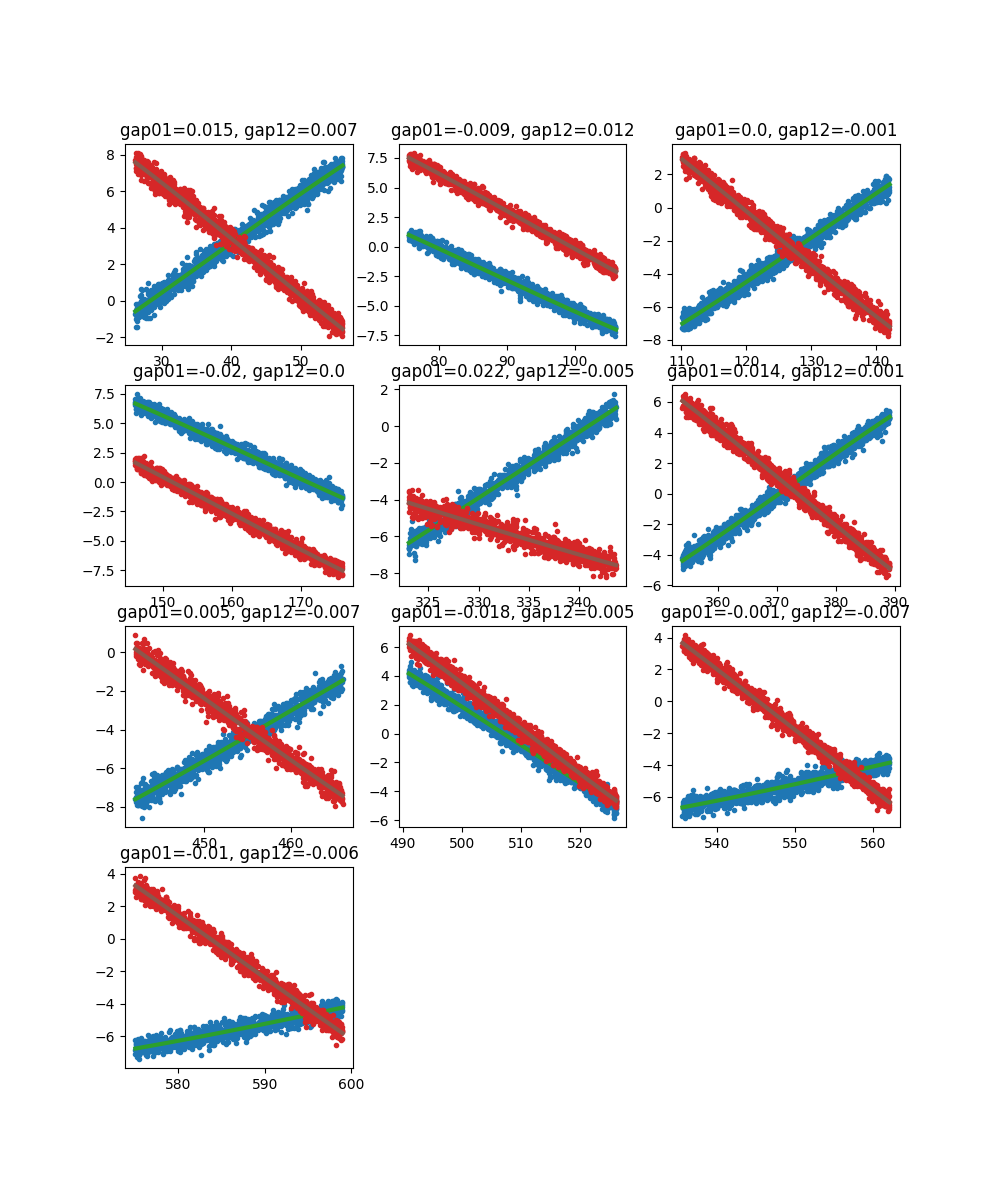

In [37]:
# first cheat by using the gt location to get the random phase offset (mean value for all satellites)
from sat_id import aoa_sim_1_sat, aoa_sim_1_sat_eph

# tracked tones' phase diff
del_phi_repeat_01_list, del_phi_repeat_12_list, coeff_01_list, coeff_12_list, del_phi_01_gt_list, del_phi_12_gt_list, t_sim_arr, az_gt_list, el_gt_list, range_gt_list = [], [], [], [], [], [], [], [], [], []
d, lam = 13.25e-2, 299792458/fc
loc_1, loc_0, loc_2 = np.array([0,0,0]), np.array([0,-d,0]), np.array([d,0,0])

# yaw_arr = np.arange(0,10,1)
# pitch_arr = np.arange(0,10,1)
# roll_arr = np.arange(0,10,1)
# yaw, pitch, roll = 1,0,0
##### commenting out the orientation part for synthetic data
# # consider orientation - 2: yaw, pitch, roll from imudata
# orient = imu.get_attitude()
# yaw, pitch, roll = np.mean(orient[2][-3000:-1]), np.mean(orient[1]), np.mean(orient[0])
# # yaw = 0
# R_yaw = np.array([[np.cos(np.deg2rad(yaw)), -np.sin(np.deg2rad(yaw)), 0], [np.sin(np.deg2rad(yaw)), np.cos(np.deg2rad(yaw)), 0], [0, 0, 1]])
# R_pitch = np.array([[np.cos(np.deg2rad(pitch)), 0, np.sin(np.deg2rad(pitch))], [0, 1, 0], [-np.sin(np.deg2rad(pitch)), 0, np.cos(np.deg2rad(pitch))]])
# R_roll = np.array([[1, 0, 0], [0, np.cos(np.deg2rad(roll)), -np.sin(np.deg2rad(roll))], [0, np.sin(np.deg2rad(roll)), np.cos(np.deg2rad(roll))]])
# R = R_yaw @ R_pitch @ R_roll
# loc_0, loc_2 = R @ loc_0, R @ loc_2

# first solve ambiguity
gap_01_arr, gap_12_arr = np.array([]), np.array([]) 
gap_01_coarse_arr, gap_12_coarse_arr = np.array([]), np.array([])
for sat_idx in range(sat_num):
    # time for tracked tones
    dopp_track = dopp_track_dict[0, sat_idx]
    t_repeat = dopp_track[:, 0].real
    t_sat_start, t_sat_end = t_repeat[0], t_repeat[-1]

    # gt location
    t_sim, az_gt, el_gt, range_gt = aoa_sim_1_sat(date, date+'/Starlink.tle', id_dict[0,sat_idx][0], start_time+t_sat_start, start_time+t_sat_end, .1, lat_gt, lon_gt, alt_gt)
    t_sim += t_sat_start
    az_gt, el_gt = np.deg2rad(az_gt), np.deg2rad(el_gt)

    # coarse location
    _, az_coarse, el_coarse, range_coarse = aoa_sim_1_sat(date, date+'/Starlink.tle', id_dict[0,sat_idx][0], start_time+t_sat_start, start_time+t_sat_end, .1, coarse_gs_lat, coarse_gs_lon)
    az_coarse, el_coarse = np.deg2rad(az_coarse), np.deg2rad(el_coarse)
    
    loc_sat = np.column_stack((range_gt * np.cos(el_gt) * np.sin(az_gt), range_gt * np.cos(el_gt) * np.cos(az_gt), range_gt * np.sin(el_gt)))
    loc_sat_coarse = np.column_stack((range_coarse * np.cos(el_coarse) * np.sin(az_coarse), range_coarse * np.cos(el_coarse) * np.cos(az_coarse), range_coarse * np.sin(el_coarse)))
    # subtract the ref sig's phase : TODO set to 0 for synthesized data
    # ref_sig_ii = np.argmin(np.abs(ref_sig_idx[:, 0]/sample_rate-(t_sat_start+t_sat_end)/2))
    phase_offset_01_ = 0
    phase_offset_12_ = 0
    # print('phase_offset_01, phase_offset_12: ', phase_offset_01_, phase_offset_12_)
    # delta phi from measured dopp
    del_phi_repeat_01 = np.unwrap(np.angle(dopp_track[:, 2])-np.angle(dopp_track[:, 3])) - phase_offset_01_
    del_phi_repeat_12 = np.unwrap(np.angle(dopp_track[:, 3])-np.angle(dopp_track[:, 4])) - phase_offset_12_
    
    # delta phi from simulation
    range_1 = np.linalg.norm(loc_sat-loc_1, axis=1)
    range_0 = np.linalg.norm(loc_sat-loc_0, axis=1)
    range_2 = np.linalg.norm(loc_sat-loc_2, axis=1)
    del_phi_01_gt = -(range_0-range_1)/lam*2*np.pi
    del_phi_12_gt = -(range_1-range_2)/lam*2*np.pi

    range_1_coarse = np.linalg.norm(loc_sat_coarse-loc_1, axis=1)
    range_0_coarse = np.linalg.norm(loc_sat_coarse-loc_0, axis=1)
    range_2_coarse = np.linalg.norm(loc_sat_coarse-loc_2, axis=1)
    del_phi_01_coarse = -(range_0_coarse-range_1_coarse)/lam*2*np.pi
    del_phi_12_coarse = -(range_1_coarse-range_2_coarse)/lam*2*np.pi

    # calculate gap
    coeff_01 = np.polyfit(t_repeat, del_phi_repeat_01, 2, w=np.minimum(np.abs(dopp_track[:, 2]), np.abs(dopp_track[:, 3])))
    coeff_12 = np.polyfit(t_repeat, del_phi_repeat_12, 2, w=np.minimum(np.abs(dopp_track[:, 3]), np.abs(dopp_track[:, 4])))
    # gap_01 = np.mean(del_phi_01_gt-np.polyval(coeff_01, t_sim)).real
    # gap_12 = np.mean(del_phi_12_gt-np.polyval(coeff_12, t_sim)).real
    gap_01_coarse = np.mean(del_phi_01_coarse-np.polyval(coeff_01, t_sim)).real
    gap_12_coarse = np.mean(del_phi_12_coarse-np.polyval(coeff_12, t_sim)).real

    while np.abs(gap_01_coarse-np.mean(gap_01_coarse_arr)) > 1.5*np.pi:
        tmp = 2*np.pi*np.sign(gap_01_coarse-np.mean(gap_01_arr))
        gap_01_coarse -= tmp
        del_phi_repeat_01 += tmp
    while np.abs(gap_12_coarse-np.mean(gap_12_coarse_arr)) > 1.5*np.pi:
        tmp = 2*np.pi*np.sign(gap_12_coarse-np.mean(gap_12_arr))
        gap_12_coarse -= tmp
        del_phi_repeat_12 += tmp

    gap_01_coarse_arr = np.append(gap_01_coarse_arr, gap_01_coarse)
    gap_12_coarse_arr = np.append(gap_12_coarse_arr, gap_12_coarse)

    coeff_01 = np.polyfit(t_repeat, del_phi_repeat_01, 2, w=np.minimum(np.abs(dopp_track[:, 2]), np.abs(dopp_track[:, 3])))
    coeff_12 = np.polyfit(t_repeat, del_phi_repeat_12, 2, w=np.minimum(np.abs(dopp_track[:, 3]), np.abs(dopp_track[:, 4])))
    gap_01 = np.mean(del_phi_01_gt-np.polyval(coeff_01, t_sim)).real
    gap_12 = np.mean(del_phi_12_gt-np.polyval(coeff_12, t_sim)).real


    # fit the discrete data points with polynomial (second order)
    coeff_01_list.append(np.polyfit(t_repeat, del_phi_repeat_01, 2, w=np.minimum(np.abs(dopp_track[:, 2]), np.abs(dopp_track[:, 3]))))
    coeff_12_list.append(np.polyfit(t_repeat, del_phi_repeat_12, 2, w=np.minimum(np.abs(dopp_track[:, 3]), np.abs(dopp_track[:, 4]))))
    del_phi_repeat_01_list.append(del_phi_repeat_01)
    del_phi_repeat_12_list.append(del_phi_repeat_12)
    del_phi_01_gt_list.append(del_phi_01_gt)
    del_phi_12_gt_list.append(del_phi_12_gt)
    gap_01_arr = np.append(gap_01_arr, gap_01)
    gap_12_arr = np.append(gap_12_arr, gap_12)
    az_gt_list.append(az_gt)
    el_gt_list.append(el_gt)
    range_gt_list.append(range_gt)
    t_sim_arr.append(t_sim)

# plot a large fig
plt.figure(figsize=(10, 12))
for sat_idx in range(sat_num):
    dopp_track = dopp_track_dict[0, sat_idx]
    t_sim = t_sim_arr[sat_idx]
    plt.subplot(4, 3, sat_idx+1)
    plt.plot(dopp_track[:, 0], del_phi_repeat_01_list[sat_idx]+np.mean(gap_01_arr), '.')
    plt.plot(t_sim, np.polyval(coeff_01_list[sat_idx], t_sim)+np.mean(gap_01_arr), label='fit', linestyle='--')
    plt.plot(t_sim, del_phi_01_gt_list[sat_idx], label='gt', linewidth=3)
    plt.plot(dopp_track[:, 0], del_phi_repeat_12_list[sat_idx]+np.mean(gap_12_arr), '.')
    plt.plot(t_sim, np.polyval(coeff_12_list[sat_idx], t_sim)+np.mean(gap_12_arr), label='fit', linestyle='--')
    plt.plot(t_sim, del_phi_12_gt_list[sat_idx], label='gt', linewidth=3)
    # plt.legend()
    plt.title('gap01='+str(round(gap_01_arr[sat_idx]-np.mean(gap_01_arr),3))+', gap12='+str(round(gap_12_arr[sat_idx]-np.mean(gap_12_arr),3)))
plt.show()

In [38]:
# do grid search for all satellites
from tqdm import tqdm
x_grid, y_grid = np.linspace(-10e3, 10e3, 400), np.linspace(-10e3, 10e3, 400)
err_min = np.inf
num_sat_for_training = round(sat_num/2)
num_sat_for_testing = sat_num - num_sat_for_training
for x in x_grid:
    for y in y_grid:
        err = 0
        # add some offset to the ground truth location
        loc_1_, loc_0_, loc_2_ = loc_1+np.array([x,y,0]), loc_0+np.array([x,y,0]), loc_2+np.array([x,y,0])
        for sat_idx in range(sat_num):
            if sat_idx < num_sat_for_training:
                continue

            t_sim = t_sim_arr[sat_idx]
            mes_12 = np.polyval(coeff_12_list[sat_idx], t_sim)+np.mean(gap_12_arr[0:num_sat_for_training])
            mes_01 = np.polyval(coeff_01_list[sat_idx], t_sim)+np.mean(gap_01_arr[0:num_sat_for_training])
            # mes_12 = np.polyval(coeff_12_list[sat_idx], t_sim)+gap_12_arr[sat_idx]
            # mes_01 = np.polyval(coeff_01_list[sat_idx], t_sim)+gap_01_arr[sat_idx]
            mes_12_diff = np.diff(mes_12)
            mes_01_diff = np.diff(mes_01)
            
            az_gt, el_gt, range_gt = az_gt_list[sat_idx], el_gt_list[sat_idx], range_gt_list[sat_idx]
            loc_sat = np.column_stack((range_gt * np.cos(el_gt) * np.sin(az_gt),
                         range_gt * np.cos(el_gt) * np.cos(az_gt),
                         range_gt * np.sin(el_gt)))    # the unit vector pointing to the sat from the origin

            range_1 = np.linalg.norm(loc_sat-loc_1_, axis=1)
            range_0 = np.linalg.norm(loc_sat-loc_0_, axis=1)
            range_2 = np.linalg.norm(loc_sat-loc_2_, axis=1)
            del_phi_01_gt = -(range_0-range_1)/lam*2*np.pi
            del_phi_12_gt = -(range_1-range_2)/lam*2*np.pi

            
            err += np.sum(np.abs(mes_12-del_phi_12_gt))*(pw_list_1[sat_idx]+pw_list_2[sat_idx]) + np.sum(np.abs(mes_01-del_phi_01_gt))*(pw_list_0[sat_idx]+pw_list_1[sat_idx])
            # err += np.sum(np.abs(mes_12_diff-np.diff(del_phi_12_gt)))+np.sum(np.abs(mes_01_diff-np.diff(del_phi_01_gt)))
        # print(err)
        if err < err_min:
            err_min = err
            loc_min = np.array([x,y])
loc_aoa_overall_2d = loc_min
loc_aoa_overall_err = np.linalg.norm(loc_aoa_overall_2d)
# print(loc_aoa_overall_2d, loc_aoa_overall_err)

loc_aoa_list = []
for i in tqdm(range(num_sat_for_training, sat_num)):
    err_min = np.inf
    for x in x_grid:
        for y in y_grid:
            err = 0
            # add some offset to the ground truth location
            loc_1_, loc_0_, loc_2_ = loc_1+np.array([x,y,0]), loc_0+np.array([x,y,0]), loc_2+np.array([x,y,0])
            for sat_idx in [i]:
                t_sim = t_sim_arr[sat_idx]
                mes_12 = np.polyval(coeff_12_list[sat_idx], t_sim)+np.mean(gap_12_arr[0:num_sat_for_training])
                mes_01 = np.polyval(coeff_01_list[sat_idx], t_sim)+np.mean(gap_01_arr[0:num_sat_for_training])
                # mes_12 = np.polyval(coeff_12_list[sat_idx], t_sim)+gap_12_arr[sat_idx]
                # mes_01 = np.polyval(coeff_01_list[sat_idx], t_sim)+gap_01_arr[sat_idx]
                mes_12_diff = np.diff(mes_12)
                mes_01_diff = np.diff(mes_01)
                
                az_gt, el_gt, range_gt = az_gt_list[sat_idx], el_gt_list[sat_idx], range_gt_list[sat_idx]
                loc_sat = np.column_stack((range_gt * np.cos(el_gt) * np.sin(az_gt),
                            range_gt * np.cos(el_gt) * np.cos(az_gt),
                            range_gt * np.sin(el_gt)))    # the unit vector pointing to the sat from the origin

                range_1 = np.linalg.norm(loc_sat-loc_1_, axis=1)
                range_0 = np.linalg.norm(loc_sat-loc_0_, axis=1)
                range_2 = np.linalg.norm(loc_sat-loc_2_, axis=1)
                del_phi_01_gt = -(range_0-range_1)/lam*2*np.pi
                del_phi_12_gt = -(range_1-range_2)/lam*2*np.pi

                if sat_idx < num_sat_for_training:
                    continue
                err += np.sum(np.abs(mes_12-del_phi_12_gt))*(pw_list_1[sat_idx]+pw_list_2[sat_idx]) + np.sum(np.abs(mes_01-del_phi_01_gt))*(pw_list_0[sat_idx]+pw_list_1[sat_idx])
                # err += np.sum(np.abs(mes_12_diff-np.diff(del_phi_12_gt)))+np.sum(np.abs(mes_01_diff-np.diff(del_phi_01_gt)))
            # print(err)
            if err < err_min:
                err_min = err
                loc_min = np.array([x,y])
    loc_aoa_list.append(loc_min)

print(loc_aoa_overall_2d, loc_aoa_overall_err)
for i in range(num_sat_for_testing):
    print('sat #'+str(i+num_sat_for_training), loc_aoa_list[i], np.linalg.norm(loc_aoa_list[i]))


100%|██████████| 5/5 [00:47<00:00,  9.51s/it]

[175.43859649  75.18796992] 190.87150641263045
sat #5 [ -25.06265664 -225.56390977] 226.95200847462095
sat #6 [ 175.43859649 -175.43859649] 248.1076425215956
sat #7 [-25.06265664 375.93984962] 376.7743453226301
sat #8 [275.68922306  25.06265664] 276.8260906563233
sat #9 [175.43859649 175.43859649] 248.1076425215969


In [ ]:
for sat in loc_aoa_list:
    print(np.linalg.norm(sat))

79.25507920221386
127.79497527801536
146.13914523421835
226.95200847462294
237.7652376066462


Doppler based loc

In [10]:
from sat_id import dopp_sim_1_sat
p_list ,tt_sim_list, az_gt_dopp_list, el_gt_dopp_list, range_gt_dopp_list = [], [], [], [], []
for sat_idx in range(sat_num):
    dopp_track = dopp_track_main_dict[0, sat_idx]
    t_repeat = dopp_track[:, 0].real
    dopp_repeat = dopp_track[:, 1].real
    t_sat_start, t_sat_end = np.min(t_repeat), np.max(t_repeat)

    t_sim, dopp_coarse, _, _, _ = dopp_sim_1_sat(date, date+'/Starlink.tle', id_dict[0,sat_idx][0], start_time+t_sat_start, start_time+t_sat_end, .01, coarse_gs_lat, coarse_gs_lon, alt_gt)
    t_sim += t_sat_start

    _, dopp_gt, az_gt, el_gt, range_gt = dopp_sim_1_sat(date, date+'/Starlink.tle', id_dict[0,sat_idx][0], start_time+t_sat_start, start_time+t_sat_end, .01, lat_gt, lon_gt, alt_gt)

    p = np.polyfit(t_repeat, dopp_repeat, 3, w=np.abs(dopp_track[:, 2]))
    freq_offset_ = np.mean(dopp_coarse - np.polyval(p, t_sim))
    p = np.polyfit(t_repeat, dopp_repeat+freq_offset_, 3, w=np.abs(dopp_track[:, 2]))
    
    tt_sim_list.append(t_sim)
    p_list.append(p)
    az_gt_dopp_list.append(np.deg2rad(az_gt))
    el_gt_dopp_list.append(np.deg2rad(el_gt))
    range_gt_dopp_list.append(range_gt)


Optimization based dopp

In [11]:
from scipy.optimize import least_squares
t_step = tt_sim_list[0][1] - tt_sim_list[0][0]
loc_sat_list, dopp_gt_list = [], []
for sat_idx in range(sat_num):
    range_gt, az_gt, el_gt = range_gt_dopp_list[sat_idx], az_gt_dopp_list[sat_idx], el_gt_dopp_list[sat_idx]
    loc_sat = np.column_stack((range_gt * np.cos(el_gt) * np.sin(az_gt), range_gt * np.cos(el_gt) * np.cos(az_gt), range_gt * np.sin(el_gt))) 
    loc_sat_list.append(loc_sat)

    p = p_list[sat_idx]
    t_sim = tt_sim_list[sat_idx]
    # dopp_gt_list.append(np.polyval(p, t_sim[0:-1]+(t_step)/2) - np.polyval(p, time_arr[sat_idx]))
    dopp_gt_list.append(np.polyval(p, t_sim[0:-1]+(t_step)/2))
    
def residual(params, loc_sat_list, dopp_gt_list, pw_list, fc, t_step, train_num, sat_idx=None):
    c = 299792458
    x, y = params[0], params[1]
    num_sats = len(loc_sat_list)
    loc_rx = np.array([x, y, 0])
    err = 0
    if sat_idx == None:
        for sat_idx in range(train_num, num_sats):
            loc_sat = loc_sat_list[sat_idx]
            dopp_gt = dopp_gt_list[sat_idx]
            the_range = np.linalg.norm(loc_sat-loc_rx, axis=1)
            the_range_rate = np.diff(the_range)/t_step
            dopp = -the_range_rate * fc / c + params[sat_idx+2]
            err += np.linalg.norm(dopp-dopp_gt)*pw_list[sat_idx]
    else:
        loc_sat = loc_sat_list[sat_idx]
        dopp_gt = dopp_gt_list[sat_idx]
        the_range = np.linalg.norm(loc_sat-loc_rx, axis=1)
        the_range_rate = np.diff(the_range)/t_step
        dopp = -the_range_rate * fc / c + params[sat_idx+2]
        err = np.linalg.norm(dopp-dopp_gt)
    return err
np.random.seed(42)
# overall result
initial_guess = [loc_aoa_overall_2d[0], loc_aoa_overall_2d[1], 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
result = least_squares(residual, initial_guess, args=(loc_sat_list, dopp_gt_list, pw_list_0, fc, t_step, num_sat_for_training))
loc_dopp_overall_2d = result.x[0:2]
loc_dopp_overall_err = np.linalg.norm(loc_dopp_overall_2d)
loc_dopp_list = []
for sat_idx in range(num_sat_for_training, sat_num):
    ii = sat_idx - num_sat_for_training
    initial_guess = [loc_aoa_list[ii][0], loc_aoa_list[ii][1], 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
    result_ii = least_squares(residual, initial_guess, args=(loc_sat_list, dopp_gt_list, pw_list_0, fc, t_step, num_sat_for_training, sat_idx))
    loc_dopp_list.append(result_ii.x[0:2])

Grid search based

In [12]:
from sat_id import dopp_sim_1_sat
p_list ,tt_sim_list, az_gt_dopp_list, el_gt_dopp_list, range_gt_dopp_list = [], [], [], [], []
for sat_idx in range(sat_num):
    dopp_track = dopp_track_main_dict[0, sat_idx]
    t_repeat = dopp_track[:, 0].real
    dopp_repeat = dopp_track[:, 1].real
    t_sat_start, t_sat_end = np.min(t_repeat), np.max(t_repeat)

    t_sim, dopp_gt, az_gt, el_gt, range_gt = dopp_sim_1_sat(date, date+'/Starlink.tle', id_dict[0,sat_idx][0], start_time+t_sat_start, start_time+t_sat_end, .001, lat_gt, lon_gt, alt_gt)
    t_sim += t_sat_start

    p = np.polyfit(t_repeat, dopp_repeat, 3, w=np.abs(dopp_track[:, 2]))
    freq_offset_ = np.polyval(p, time_arr[sat_idx])
    p = np.polyfit(t_repeat, dopp_repeat-freq_offset_, 3, w=np.abs(dopp_track[:, 2]))
    
    tt_sim_list.append(t_sim)
    p_list.append(p)
    az_gt_dopp_list.append(np.deg2rad(az_gt))
    el_gt_dopp_list.append(np.deg2rad(el_gt))
    range_gt_dopp_list.append(range_gt)


100%|██████████| 10/10 [09:02<00:00, 54.30s/it]


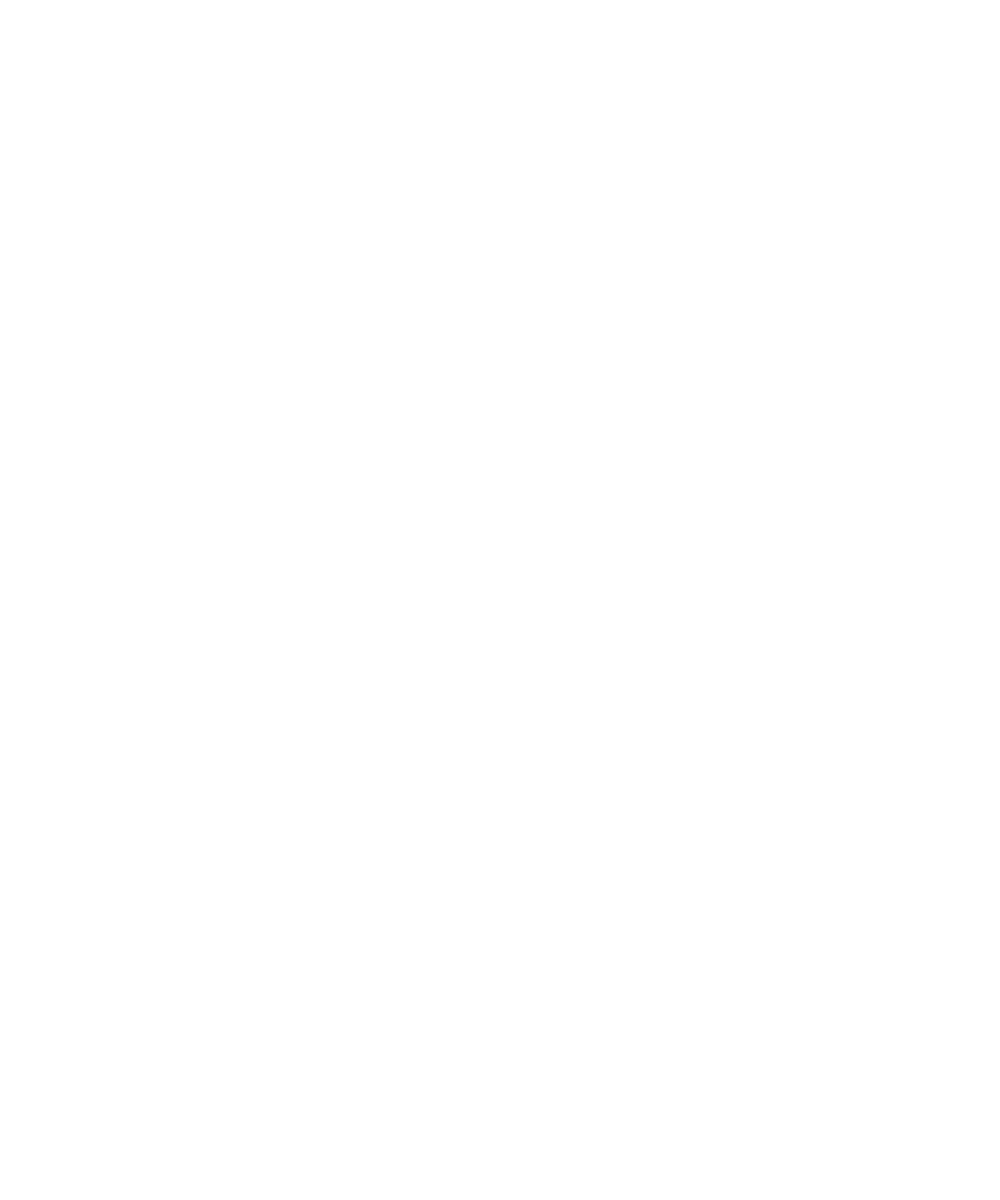

In [15]:
t_step = tt_sim_list[0][1] - tt_sim_list[0][0]
loc_sat_list, dopp_gt_list = [], []
plt.clf()
for sat_idx in range(sat_num):
    range_gt, az_gt, el_gt = range_gt_dopp_list[sat_idx], az_gt_dopp_list[sat_idx], el_gt_dopp_list[sat_idx]
    loc_sat = np.column_stack((range_gt * np.cos(el_gt) * np.sin(az_gt), range_gt * np.cos(el_gt) * np.cos(az_gt), range_gt * np.sin(el_gt))) 
    loc_sat_list.append(loc_sat)

    p = p_list[sat_idx]
    t_sim = tt_sim_list[sat_idx]
    # dopp_gt_list.append(np.polyval(p, t_sim[0:-1]+(t_step)/2) - np.polyval(p, time_arr[sat_idx]))
    dopp_gt_list.append(np.polyval(p, t_sim[0:-1]+(t_step)/2))
    # plt.plot(t_sim[0:-1]+(t_step)/2, np.polyval(p, t_sim[0:-1]+(t_step)/2), label='fit')
loc_dopp_grid_list = []
x_grid, y_grid = np.linspace(-10e3, 10e3, 400), np.linspace(-10e3, 10e3, 400)
for sat_idx in tqdm(range(sat_num)):
    err_min = np.inf
    if not is_middle_arr[sat_idx]:
        continue
    for x in x_grid:
        for y in y_grid:
            err = 0
            # add some offset to the ground truth location
            loc_sat = loc_sat_list[sat_idx]
            dopp_gt = dopp_gt_list[sat_idx]
            the_range = np.linalg.norm(loc_sat-np.array([x,y,0]), axis=1)
            the_range_rate = np.diff(the_range)/t_step
            dopp = -the_range_rate * fc / 299792458
            t_sim = tt_sim_list[sat_idx]
            # plt.plot(t_sim[0:-1]+(t_step)/2, dopp)
            # plt.plot(t_sim[0:-1]+(t_step)/2, dopp_gt, '--')
            err = np.linalg.norm(dopp-dopp_gt)
            if err < err_min:
                err_min = err
                loc_min_dopp_grid = np.array([x,y])
    loc_dopp_grid_list.append(loc_min_dopp_grid)
plt.show()
# print(loc_aoa_overall_2d, loc_aoa_overall_err)
# for i in range(num_sat_for_testing):
    # print('sat #'+str(i+num_sat_for_training), loc_aoa_list[i], np.linalg.norm(loc_aoa_list[i]))

In [17]:
loc_dopp_grid_list

[array([10000.        ,  4185.46365915]),
 array([ 927.31829574, -827.06766917]),
 array([-1328.32080201,  1278.19548872]),
 array([-10000.        ,  -6190.47619048]),
 array([-275.68922306, -125.31328321]),
 array([ -977.44360902, 10000.        ]),
 array([ -125.31328321, -1729.32330827]),
 array([10000., 10000.]),
 array([-1378.44611529, -1929.8245614 ]),
 array([ 3032.58145363, -3984.96240602])]

In [14]:
# print all results
print('capture '+ date)
print('1. ground truth lat, lon in degrees')
print(lat_gt, lon_gt)
print('2. coarse lat, lon in degrees')
print(coarse_gs_lat, coarse_gs_lon)
print('3. coarse location error in kilometers')
print(get_distkm_latlon_coordinates([lat_gt, lon_gt], [coarse_gs_lat, coarse_gs_lon])[0])
print('4. total satellite number, number of satellites for training')
print(sat_num, num_sat_for_training)
print('5. phase based overall result: 2d in meters, error in meters')
print(loc_aoa_overall_2d[0], loc_aoa_overall_2d[1], loc_aoa_overall_err)
print('6. doppler based overall result: 2d in meters, error in meters')
print(loc_dopp_overall_2d[0], loc_dopp_overall_2d[1], loc_dopp_overall_err)
print('7. avearge overall loc result')
print((loc_aoa_overall_2d[0]+loc_dopp_overall_2d[0])/2, (loc_aoa_overall_2d[1]+loc_dopp_overall_2d[1])/2, np.sqrt(((loc_aoa_overall_2d[0]+loc_dopp_overall_2d[0])/2)**2+((loc_aoa_overall_2d[1]+loc_dopp_overall_2d[1])/2)**2))
print('8. individual satellite results - phase based')
for i in range(num_sat_for_testing):
    print('sat #'+str(i+num_sat_for_training), loc_aoa_list[i][0], loc_aoa_list[i][1], np.linalg.norm(loc_aoa_list[i]))
print('9. individual satellite results - doppler based')
for i in range(num_sat_for_testing):
    print('sat #'+str(i+num_sat_for_training), loc_dopp_list[i][0], loc_dopp_list[i][1], np.linalg.norm(loc_dopp_list[i]))
print('10. individual satellite results - doppler + phase')
for i in range(num_sat_for_testing):
    print('sat #'+str(i+num_sat_for_training), (loc_aoa_list[i][0]+loc_dopp_list[i][0])/2, (loc_aoa_list[i][1]+loc_dopp_list[i][1])/2, np.linalg.norm((loc_aoa_list[i]+loc_dopp_list[i])/2))

capture 30Jun2024_06_00_00_synthetic
1. ground truth lat, lon in degrees
40.11389690596162 -88.22484814695467
2. coarse lat, lon in degrees
40.10743428260823 -88.09616012205979
3. coarse location error in kilometers
10.96745959181056
4. total satellite number, number of satellites for training
10 5
5. phase based overall result: 2d in meters, error in meters
125.31328320802095 75.18796992481293 146.13914523421928
6. doppler based overall result: 2d in meters, error in meters
4620.4278308222665 -1810.2725919204229 4962.402663719989
7. avearge overall loc result
2372.8705570151437 -867.542310997805 2526.488539796049
8. individual satellite results - phase based
sat #5 -25.0626566416031 -75.18796992481111 79.25507920221386
sat #6 125.31328320802095 -25.0626566416031 127.79497527801536
sat #7 -75.18796992481111 125.31328320802095 146.13914523421835
sat #8 225.56390977443698 25.062656641604917 226.95200847462294
sat #9 75.18796992481293 225.56390977443698 237.7652376066462
9. individual sat

### Ablation Study for Orientation Errors

In [ ]:
# first cheat by using the gt location to get the random phase offset (mean value for all satellites)
from sat_id import aoa_sim_1_sat, aoa_sim_1_sat_eph

# tracked tones' phase diff
del_phi_repeat_01_list, del_phi_repeat_12_list, coeff_01_list, coeff_12_list, del_phi_01_gt_list, del_phi_12_gt_list, t_sim_arr, az_gt_list, el_gt_list, range_gt_list = [], [], [], [], [], [], [], [], [], []
d, lam = 13.25e-2, 299792458/fc
loc_1, loc_0, loc_2 = np.array([0,0,0]), np.array([0,-d,0]), np.array([d,0,0])

yaw_arr = np.arange(0,5,0.5)
pitch, roll = 0, 0
# pitch_arr = np.arange(0,10,1)
# roll_arr = np.arange(0,10,1)
# yaw, pitch, roll = 1,0,0
for yaw in yaw_arr:
    ##### commenting out the orientation part for synthetic data
    # # consider orientation - 2: yaw, pitch, roll from imudata
    # orient = imu.get_attitude()
    # yaw, pitch, roll = np.mean(orient[2][-3000:-1]), np.mean(orient[1]), np.mean(orient[0])
    # # yaw = 0
    R_yaw = np.array([[np.cos(np.deg2rad(yaw)), -np.sin(np.deg2rad(yaw)), 0], [np.sin(np.deg2rad(yaw)), np.cos(np.deg2rad(yaw)), 0], [0, 0, 1]])
    R_pitch = np.array([[np.cos(np.deg2rad(pitch)), 0, np.sin(np.deg2rad(pitch))], [0, 1, 0], [-np.sin(np.deg2rad(pitch)), 0, np.cos(np.deg2rad(pitch))]])
    R_roll = np.array([[1, 0, 0], [0, np.cos(np.deg2rad(roll)), -np.sin(np.deg2rad(roll))], [0, np.sin(np.deg2rad(roll)), np.cos(np.deg2rad(roll))]])
    R = R_yaw @ R_pitch @ R_roll
    loc_0, loc_2 = R @ loc_0, R @ loc_2

    # first solve ambiguity
    gap_01_arr, gap_12_arr = np.array([]), np.array([]) 
    gap_01_coarse_arr, gap_12_coarse_arr = np.array([]), np.array([])
    for sat_idx in range(sat_num):
        # time for tracked tones
        dopp_track = dopp_track_dict[0, sat_idx]
        t_repeat = dopp_track[:, 0].real
        t_sat_start, t_sat_end = t_repeat[0], t_repeat[-1]

        # gt location
        t_sim, az_gt, el_gt, range_gt = aoa_sim_1_sat(date, date+'/Starlink.tle', id_dict[0,sat_idx][0], start_time+t_sat_start, start_time+t_sat_end, .1, lat_gt, lon_gt, alt_gt)
        t_sim += t_sat_start
        az_gt, el_gt = np.deg2rad(az_gt), np.deg2rad(el_gt)

        # coarse location
        _, az_coarse, el_coarse, range_coarse = aoa_sim_1_sat(date, date+'/Starlink.tle', id_dict[0,sat_idx][0], start_time+t_sat_start, start_time+t_sat_end, .1, coarse_gs_lat, coarse_gs_lon)
        az_coarse, el_coarse = np.deg2rad(az_coarse), np.deg2rad(el_coarse)
        
        loc_sat = np.column_stack((range_gt * np.cos(el_gt) * np.sin(az_gt), range_gt * np.cos(el_gt) * np.cos(az_gt), range_gt * np.sin(el_gt)))
        loc_sat_coarse = np.column_stack((range_coarse * np.cos(el_coarse) * np.sin(az_coarse), range_coarse * np.cos(el_coarse) * np.cos(az_coarse), range_coarse * np.sin(el_coarse)))

        # subtract the ref sig's phase : TODO set to 0 for synthesized data
        # ref_sig_ii = np.argmin(np.abs(ref_sig_idx[:, 0]/sample_rate-(t_sat_start+t_sat_end)/2))
        phase_offset_01_ = 0
        phase_offset_12_ = 0
        # delta phi from measured dopp
        del_phi_repeat_01 = np.unwrap(np.angle(dopp_track[:, 2])-np.angle(dopp_track[:, 3])) - phase_offset_01_
        del_phi_repeat_12 = np.unwrap(np.angle(dopp_track[:, 3])-np.angle(dopp_track[:, 4])) - phase_offset_12_
        
        # delta phi from simulation
        range_1 = np.linalg.norm(loc_sat-loc_1, axis=1)
        range_0 = np.linalg.norm(loc_sat-loc_0, axis=1)
        range_2 = np.linalg.norm(loc_sat-loc_2, axis=1)
        del_phi_01_gt = -(range_0-range_1)/lam*2*np.pi
        del_phi_12_gt = -(range_1-range_2)/lam*2*np.pi

        range_1_coarse = np.linalg.norm(loc_sat_coarse-loc_1, axis=1)
        range_0_coarse = np.linalg.norm(loc_sat_coarse-loc_0, axis=1)
        range_2_coarse = np.linalg.norm(loc_sat_coarse-loc_2, axis=1)
        del_phi_01_coarse = -(range_0_coarse-range_1_coarse)/lam*2*np.pi
        del_phi_12_coarse = -(range_1_coarse-range_2_coarse)/lam*2*np.pi

        # calculate gap
        coeff_01 = np.polyfit(t_repeat, del_phi_repeat_01, 2, w=np.minimum(np.abs(dopp_track[:, 2]), np.abs(dopp_track[:, 3])))
        coeff_12 = np.polyfit(t_repeat, del_phi_repeat_12, 2, w=np.minimum(np.abs(dopp_track[:, 3]), np.abs(dopp_track[:, 4])))
        # gap_01 = np.mean(del_phi_01_gt-np.polyval(coeff_01, t_sim)).real
        # gap_12 = np.mean(del_phi_12_gt-np.polyval(coeff_12, t_sim)).real
        gap_01_coarse = np.mean(del_phi_01_coarse-np.polyval(coeff_01, t_sim)).real
        gap_12_coarse = np.mean(del_phi_12_coarse-np.polyval(coeff_12, t_sim)).real

        while np.abs(gap_01_coarse-np.mean(gap_01_coarse_arr)) > 1.5*np.pi:
            tmp = 2*np.pi*np.sign(gap_01_coarse-np.mean(gap_01_arr))
            gap_01_coarse -= tmp
            del_phi_repeat_01 += tmp
        while np.abs(gap_12_coarse-np.mean(gap_12_coarse_arr)) > 1.5*np.pi:
            tmp = 2*np.pi*np.sign(gap_12_coarse-np.mean(gap_12_arr))
            gap_12_coarse -= tmp
            del_phi_repeat_12 += tmp

        gap_01_coarse_arr = np.append(gap_01_coarse_arr, gap_01_coarse)
        gap_12_coarse_arr = np.append(gap_12_coarse_arr, gap_12_coarse)

        coeff_01 = np.polyfit(t_repeat, del_phi_repeat_01, 2, w=np.minimum(np.abs(dopp_track[:, 2]), np.abs(dopp_track[:, 3])))
        coeff_12 = np.polyfit(t_repeat, del_phi_repeat_12, 2, w=np.minimum(np.abs(dopp_track[:, 3]), np.abs(dopp_track[:, 4])))
        gap_01 = np.mean(del_phi_01_gt-np.polyval(coeff_01, t_sim)).real
        gap_12 = np.mean(del_phi_12_gt-np.polyval(coeff_12, t_sim)).real

        # fit the discrete data points with polynomial (second order)
        coeff_01_list.append(np.polyfit(t_repeat, del_phi_repeat_01, 2, w=np.minimum(np.abs(dopp_track[:, 2]), np.abs(dopp_track[:, 3]))))
        coeff_12_list.append(np.polyfit(t_repeat, del_phi_repeat_12, 2, w=np.minimum(np.abs(dopp_track[:, 3]), np.abs(dopp_track[:, 4]))))
        del_phi_repeat_01_list.append(del_phi_repeat_01)
        del_phi_repeat_12_list.append(del_phi_repeat_12)
        del_phi_01_gt_list.append(del_phi_01_gt)
        del_phi_12_gt_list.append(del_phi_12_gt)
        gap_01_arr = np.append(gap_01_arr, gap_01)
        gap_12_arr = np.append(gap_12_arr, gap_12)
        az_gt_list.append(az_gt)
        el_gt_list.append(el_gt)
        range_gt_list.append(range_gt)
        t_sim_arr.append(t_sim)

    # # plot a large fig
    # plt.figure(figsize=(10, 12))
    # for sat_idx in range(sat_num):
    #     dopp_track = dopp_track_dict[0, sat_idx]
    #     t_sim = t_sim_arr[sat_idx]
    #     plt.subplot(4, 3, sat_idx+1)
    #     plt.plot(dopp_track[:, 0], del_phi_repeat_01_list[sat_idx]+np.mean(gap_01_arr), '.')
    #     plt.plot(t_sim, np.polyval(coeff_01_list[sat_idx], t_sim)+np.mean(gap_01_arr), label='fit', linestyle='--')
    #     plt.plot(t_sim, del_phi_01_gt_list[sat_idx], label='gt', linewidth=3)
    #     plt.plot(dopp_track[:, 0], del_phi_repeat_12_list[sat_idx]+np.mean(gap_12_arr), '.')
    #     plt.plot(t_sim, np.polyval(coeff_12_list[sat_idx], t_sim)+np.mean(gap_12_arr), label='fit', linestyle='--')
    #     plt.plot(t_sim, del_phi_12_gt_list[sat_idx], label='gt', linewidth=3)
        
    #     plt.title('gap01='+str(round(gap_01_arr[sat_idx]-np.mean(gap_01_arr),3))+', gap12='+str(round(gap_12_arr[sat_idx]-np.mean(gap_12_arr),3)))
    # plt.show()

    # do grid search for all satellites
    from tqdm import tqdm
    x_grid, y_grid = np.linspace(-20e3, 20e3, 400), np.linspace(-20e3, 20e3, 400)
    err_min = np.inf
    num_sat_for_training = round(sat_num/2)
    num_sat_for_testing = sat_num - num_sat_for_training
    for x in x_grid:
        for y in y_grid:
            err = 0
            # add some offset to the ground truth location
            loc_1_, loc_0_, loc_2_ = loc_1+np.array([x,y,0]), loc_0+np.array([x,y,0]), loc_2+np.array([x,y,0])
            for sat_idx in range(sat_num):
                if sat_idx < num_sat_for_training:
                    continue

                t_sim = t_sim_arr[sat_idx]
                mes_12 = np.polyval(coeff_12_list[sat_idx], t_sim)+np.mean(gap_12_arr[0:num_sat_for_training])
                mes_01 = np.polyval(coeff_01_list[sat_idx], t_sim)+np.mean(gap_01_arr[0:num_sat_for_training])
                # mes_12 = np.polyval(coeff_12_list[sat_idx], t_sim)+gap_12_arr[sat_idx]
                # mes_01 = np.polyval(coeff_01_list[sat_idx], t_sim)+gap_01_arr[sat_idx]
                mes_12_diff = np.diff(mes_12)
                mes_01_diff = np.diff(mes_01)
                
                az_gt, el_gt, range_gt = az_gt_list[sat_idx], el_gt_list[sat_idx], range_gt_list[sat_idx]
                loc_sat = np.column_stack((range_gt * np.cos(el_gt) * np.sin(az_gt),
                            range_gt * np.cos(el_gt) * np.cos(az_gt),
                            range_gt * np.sin(el_gt)))    # the unit vector pointing to the sat from the origin

                range_1 = np.linalg.norm(loc_sat-loc_1_, axis=1)
                range_0 = np.linalg.norm(loc_sat-loc_0_, axis=1)
                range_2 = np.linalg.norm(loc_sat-loc_2_, axis=1)
                del_phi_01_gt = -(range_0-range_1)/lam*2*np.pi
                del_phi_12_gt = -(range_1-range_2)/lam*2*np.pi

                
                err += np.sum(np.abs(mes_12-del_phi_12_gt))*(pw_list_1[sat_idx]+pw_list_2[sat_idx]) + np.sum(np.abs(mes_01-del_phi_01_gt))*(pw_list_0[sat_idx]+pw_list_1[sat_idx])
                # err += np.sum(np.abs(mes_12_diff-np.diff(del_phi_12_gt)))+np.sum(np.abs(mes_01_diff-np.diff(del_phi_01_gt)))
            # print(err)
            if err < err_min:
                err_min = err
                loc_min = np.array([x,y])
    loc_aoa_overall_2d = loc_min
    loc_aoa_overall_err = np.linalg.norm(loc_aoa_overall_2d)
    # print(loc_aoa_overall_2d, loc_aoa_overall_err)

    loc_aoa_list = []
    for i in tqdm(range(num_sat_for_training, sat_num)):
        err_min = np.inf
        for x in x_grid:
            for y in y_grid:
                err = 0
                # add some offset to the ground truth location
                loc_1_, loc_0_, loc_2_ = loc_1+np.array([x,y,0]), loc_0+np.array([x,y,0]), loc_2+np.array([x,y,0])
                for sat_idx in [i]:
                    t_sim = t_sim_arr[sat_idx]
                    mes_12 = np.polyval(coeff_12_list[sat_idx], t_sim)+np.mean(gap_12_arr[0:num_sat_for_training])
                    mes_01 = np.polyval(coeff_01_list[sat_idx], t_sim)+np.mean(gap_01_arr[0:num_sat_for_training])
                    # mes_12 = np.polyval(coeff_12_list[sat_idx], t_sim)+gap_12_arr[sat_idx]
                    # mes_01 = np.polyval(coeff_01_list[sat_idx], t_sim)+gap_01_arr[sat_idx]
                    mes_12_diff = np.diff(mes_12)
                    mes_01_diff = np.diff(mes_01)
                    
                    az_gt, el_gt, range_gt = az_gt_list[sat_idx], el_gt_list[sat_idx], range_gt_list[sat_idx]
                    loc_sat = np.column_stack((range_gt * np.cos(el_gt) * np.sin(az_gt),
                                range_gt * np.cos(el_gt) * np.cos(az_gt),
                                range_gt * np.sin(el_gt)))    # the unit vector pointing to the sat from the origin

                    range_1 = np.linalg.norm(loc_sat-loc_1_, axis=1)
                    range_0 = np.linalg.norm(loc_sat-loc_0_, axis=1)
                    range_2 = np.linalg.norm(loc_sat-loc_2_, axis=1)
                    del_phi_01_gt = -(range_0-range_1)/lam*2*np.pi
                    del_phi_12_gt = -(range_1-range_2)/lam*2*np.pi

                    if sat_idx < num_sat_for_training:
                        continue
                    err += np.sum(np.abs(mes_12-del_phi_12_gt))*(pw_list_1[sat_idx]+pw_list_2[sat_idx]) + np.sum(np.abs(mes_01-del_phi_01_gt))*(pw_list_0[sat_idx]+pw_list_1[sat_idx])
                    # err += np.sum(np.abs(mes_12_diff-np.diff(del_phi_12_gt)))+np.sum(np.abs(mes_01_diff-np.diff(del_phi_01_gt)))
                # print(err)
                if err < err_min:
                    err_min = err
                    loc_min = np.array([x,y])
        # print('sat #'+str(i), loc_min, np.linalg.norm(loc_min))
        loc_aoa_list.append(loc_min)

    print("yaw:", yaw)
    print("overall error:", loc_aoa_overall_2d, loc_aoa_overall_err)
    for i in range(num_sat_for_testing):
        print('sat #'+str(i+num_sat_for_training), loc_aoa_list[i], np.linalg.norm(loc_aoa_list[i]))


 40%|████      | 2/5 [00:24<00:37, 12.41s/it]


KeyboardInterrupt: 

Ablation study for satellite position offset/start_time_offset

In [ ]:
# first cheat by using the gt location to get the random phase offset (mean value for all satellites)
from sat_id import aoa_sim_1_sat, aoa_sim_1_sat_eph

# tracked tones' phase diff
del_phi_repeat_01_list, del_phi_repeat_12_list, coeff_01_list, coeff_12_list, del_phi_01_gt_list, del_phi_12_gt_list, t_sim_arr, az_gt_list, el_gt_list, range_gt_list = [], [], [], [], [], [], [], [], [], []
d, lam = 13.25e-2, 299792458/fc
loc_1, loc_0, loc_2 = np.array([0,0,0]), np.array([0,-d,0]), np.array([d,0,0])

# pitch_arr = np.arange(0,10,1)
# roll_arr = np.arange(0,10,1)
# yaw, pitch, roll = 1,0,0
start_time_0 = 1719727200.0
loc_sat_pos_dict = {}
for time_offset in np.arange(0,2,0.2):
    start_time = start_time_0 + time_offset
    ##### commenting out the orientation part for synthetic data
    # # consider orientation - 2: yaw, pitch, roll from imudata
    # orient = imu.get_attitude()
    # yaw, pitch, roll = np.mean(orient[2][-3000:-1]), np.mean(orient[1]), np.mean(orient[0])
    # # yaw = 0
    # R_yaw = np.array([[np.cos(np.deg2rad(yaw)), -np.sin(np.deg2rad(yaw)), 0], [np.sin(np.deg2rad(yaw)), np.cos(np.deg2rad(yaw)), 0], [0, 0, 1]])
    # R_pitch = np.array([[np.cos(np.deg2rad(pitch)), 0, np.sin(np.deg2rad(pitch))], [0, 1, 0], [-np.sin(np.deg2rad(pitch)), 0, np.cos(np.deg2rad(pitch))]])
    # R_roll = np.array([[1, 0, 0], [0, np.cos(np.deg2rad(roll)), -np.sin(np.deg2rad(roll))], [0, np.sin(np.deg2rad(roll)), np.cos(np.deg2rad(roll))]])
    # R = R_yaw @ R_pitch @ R_roll
    # loc_0, loc_2 = R @ loc_0, R @ loc_2

    # first solve ambiguity
    gap_01_arr, gap_12_arr = np.array([]), np.array([]) 
    gap_01_coarse_arr, gap_12_coarse_arr = np.array([]), np.array([])
    for sat_idx in range(sat_num):
        # time for tracked tones
        dopp_track = dopp_track_dict[0, sat_idx]
        t_repeat = dopp_track[:, 0].real
        t_sat_start, t_sat_end = t_repeat[0], t_repeat[-1]

        # gt location
        t_sim, az_gt, el_gt, range_gt = aoa_sim_1_sat(date, date+'/Starlink.tle', id_dict[0,sat_idx][0], start_time+t_sat_start, start_time+t_sat_end, .1, lat_gt, lon_gt, alt_gt)
        t_sim += t_sat_start
        az_gt, el_gt = np.deg2rad(az_gt), np.deg2rad(el_gt)

        # coarse location
        _, az_coarse, el_coarse, range_coarse = aoa_sim_1_sat(date, date+'/Starlink.tle', id_dict[0,sat_idx][0], start_time+t_sat_start, start_time+t_sat_end, .1, coarse_gs_lat, coarse_gs_lon)
        az_coarse, el_coarse = np.deg2rad(az_coarse), np.deg2rad(el_coarse)
        
        loc_sat = np.column_stack((range_gt * np.cos(el_gt) * np.sin(az_gt), range_gt * np.cos(el_gt) * np.cos(az_gt), range_gt * np.sin(el_gt)))
        loc_sat_coarse = np.column_stack((range_coarse * np.cos(el_coarse) * np.sin(az_coarse), range_coarse * np.cos(el_coarse) * np.cos(az_coarse), range_coarse * np.sin(el_coarse)))
        print("time offset:", time_offset)
        print("SATID:", id_dict[0,sat_idx][0])
        print("LOC GT",loc_sat)
        print("LOC GT COARSE",loc_sat_coarse)
        print("\n\n\n\n")
        if time_offset == 0.0:
            # save loc sat to loc_sat_init
            loc_sat_init = loc_sat
        else:
            loc_sat_pos_dict[time_offset] = loc_sat
        break
        # subtract the ref sig's phase : TODO set to 0 for synthesized data
        # ref_sig_ii = np.argmin(np.abs(ref_sig_idx[:, 0]/sample_rate-(t_sat_start+t_sat_end)/2))
        phase_offset_01_ = 0
        phase_offset_12_ = 0
        # delta phi from measured dopp
        del_phi_repeat_01 = np.unwrap(np.angle(dopp_track[:, 2])-np.angle(dopp_track[:, 3])) - phase_offset_01_
        del_phi_repeat_12 = np.unwrap(np.angle(dopp_track[:, 3])-np.angle(dopp_track[:, 4])) - phase_offset_12_
        
        # delta phi from simulation
        range_1 = np.linalg.norm(loc_sat-loc_1, axis=1)
        range_0 = np.linalg.norm(loc_sat-loc_0, axis=1)
        range_2 = np.linalg.norm(loc_sat-loc_2, axis=1)
        del_phi_01_gt = -(range_0-range_1)/lam*2*np.pi
        del_phi_12_gt = -(range_1-range_2)/lam*2*np.pi

        range_1_coarse = np.linalg.norm(loc_sat_coarse-loc_1, axis=1)
        range_0_coarse = np.linalg.norm(loc_sat_coarse-loc_0, axis=1)
        range_2_coarse = np.linalg.norm(loc_sat_coarse-loc_2, axis=1)
        del_phi_01_coarse = -(range_0_coarse-range_1_coarse)/lam*2*np.pi
        del_phi_12_coarse = -(range_1_coarse-range_2_coarse)/lam*2*np.pi

        # calculate gap
        coeff_01 = np.polyfit(t_repeat, del_phi_repeat_01, 2, w=np.minimum(np.abs(dopp_track[:, 2]), np.abs(dopp_track[:, 3])))
        coeff_12 = np.polyfit(t_repeat, del_phi_repeat_12, 2, w=np.minimum(np.abs(dopp_track[:, 3]), np.abs(dopp_track[:, 4])))
        # gap_01 = np.mean(del_phi_01_gt-np.polyval(coeff_01, t_sim)).real
        # gap_12 = np.mean(del_phi_12_gt-np.polyval(coeff_12, t_sim)).real
        gap_01_coarse = np.mean(del_phi_01_coarse-np.polyval(coeff_01, t_sim)).real
        gap_12_coarse = np.mean(del_phi_12_coarse-np.polyval(coeff_12, t_sim)).real

        while np.abs(gap_01_coarse-np.mean(gap_01_coarse_arr)) > 1.5*np.pi:
            tmp = 2*np.pi*np.sign(gap_01_coarse-np.mean(gap_01_arr))
            gap_01_coarse -= tmp
            del_phi_repeat_01 += tmp
        while np.abs(gap_12_coarse-np.mean(gap_12_coarse_arr)) > 1.5*np.pi:
            tmp = 2*np.pi*np.sign(gap_12_coarse-np.mean(gap_12_arr))
            gap_12_coarse -= tmp
            del_phi_repeat_12 += tmp

        gap_01_coarse_arr = np.append(gap_01_coarse_arr, gap_01_coarse)
        gap_12_coarse_arr = np.append(gap_12_coarse_arr, gap_12_coarse)

        coeff_01 = np.polyfit(t_repeat, del_phi_repeat_01, 2, w=np.minimum(np.abs(dopp_track[:, 2]), np.abs(dopp_track[:, 3])))
        coeff_12 = np.polyfit(t_repeat, del_phi_repeat_12, 2, w=np.minimum(np.abs(dopp_track[:, 3]), np.abs(dopp_track[:, 4])))
        gap_01 = np.mean(del_phi_01_gt-np.polyval(coeff_01, t_sim)).real
        gap_12 = np.mean(del_phi_12_gt-np.polyval(coeff_12, t_sim)).real

        # fit the discrete data points with polynomial (second order)
        coeff_01_list.append(np.polyfit(t_repeat, del_phi_repeat_01, 2, w=np.minimum(np.abs(dopp_track[:, 2]), np.abs(dopp_track[:, 3]))))
        coeff_12_list.append(np.polyfit(t_repeat, del_phi_repeat_12, 2, w=np.minimum(np.abs(dopp_track[:, 3]), np.abs(dopp_track[:, 4]))))
        del_phi_repeat_01_list.append(del_phi_repeat_01)
        del_phi_repeat_12_list.append(del_phi_repeat_12)
        del_phi_01_gt_list.append(del_phi_01_gt)
        del_phi_12_gt_list.append(del_phi_12_gt)
        gap_01_arr = np.append(gap_01_arr, gap_01)
        gap_12_arr = np.append(gap_12_arr, gap_12)
        az_gt_list.append(az_gt)
        el_gt_list.append(el_gt)
        range_gt_list.append(range_gt)
        t_sim_arr.append(t_sim)

    # # # plot a large fig
    # # plt.figure(figsize=(10, 12))
    # # for sat_idx in range(sat_num):
    # #     dopp_track = dopp_track_dict[0, sat_idx]
    # #     t_sim = t_sim_arr[sat_idx]
    # #     plt.subplot(4, 3, sat_idx+1)
    # #     plt.plot(dopp_track[:, 0], del_phi_repeat_01_list[sat_idx]+np.mean(gap_01_arr), '.')
    # #     plt.plot(t_sim, np.polyval(coeff_01_list[sat_idx], t_sim)+np.mean(gap_01_arr), label='fit', linestyle='--')
    # #     plt.plot(t_sim, del_phi_01_gt_list[sat_idx], label='gt', linewidth=3)
    # #     plt.plot(dopp_track[:, 0], del_phi_repeat_12_list[sat_idx]+np.mean(gap_12_arr), '.')
    # #     plt.plot(t_sim, np.polyval(coeff_12_list[sat_idx], t_sim)+np.mean(gap_12_arr), label='fit', linestyle='--')
    # #     plt.plot(t_sim, del_phi_12_gt_list[sat_idx], label='gt', linewidth=3)
        
    # #     plt.title('gap01='+str(round(gap_01_arr[sat_idx]-np.mean(gap_01_arr),3))+', gap12='+str(round(gap_12_arr[sat_idx]-np.mean(gap_12_arr),3)))
    # # plt.show()

    # # do grid search for all satellites
    # from tqdm import tqdm
    # x_grid, y_grid = np.linspace(-30e3, 30e3, 600), np.linspace(-30e3, 30e3, 600)
    # err_min = np.inf
    # num_sat_for_training = round(sat_num/2)
    # num_sat_for_testing = sat_num - num_sat_for_training
    # for x in x_grid:
    #     for y in y_grid:
    #         err = 0
    #         # add some offset to the ground truth location
    #         loc_1_, loc_0_, loc_2_ = loc_1+np.array([x,y,0]), loc_0+np.array([x,y,0]), loc_2+np.array([x,y,0])
    #         for sat_idx in range(sat_num):
    #             if sat_idx < num_sat_for_training:
    #                 continue

    #             t_sim = t_sim_arr[sat_idx]
    #             mes_12 = np.polyval(coeff_12_list[sat_idx], t_sim)+np.mean(gap_12_arr[0:num_sat_for_training])
    #             mes_01 = np.polyval(coeff_01_list[sat_idx], t_sim)+np.mean(gap_01_arr[0:num_sat_for_training])
    #             # mes_12 = np.polyval(coeff_12_list[sat_idx], t_sim)+gap_12_arr[sat_idx]
    #             # mes_01 = np.polyval(coeff_01_list[sat_idx], t_sim)+gap_01_arr[sat_idx]
    #             mes_12_diff = np.diff(mes_12)
    #             mes_01_diff = np.diff(mes_01)
                
    #             az_gt, el_gt, range_gt = az_gt_list[sat_idx], el_gt_list[sat_idx], range_gt_list[sat_idx]
    #             loc_sat = np.column_stack((range_gt * np.cos(el_gt) * np.sin(az_gt),
    #                         range_gt * np.cos(el_gt) * np.cos(az_gt),
    #                         range_gt * np.sin(el_gt)))    # the unit vector pointing to the sat from the origin

    #             range_1 = np.linalg.norm(loc_sat-loc_1_, axis=1)
    #             range_0 = np.linalg.norm(loc_sat-loc_0_, axis=1)
    #             range_2 = np.linalg.norm(loc_sat-loc_2_, axis=1)
    #             del_phi_01_gt = -(range_0-range_1)/lam*2*np.pi
    #             del_phi_12_gt = -(range_1-range_2)/lam*2*np.pi

                
    #             err += np.sum(np.abs(mes_12-del_phi_12_gt))*(pw_list_1[sat_idx]+pw_list_2[sat_idx]) + np.sum(np.abs(mes_01-del_phi_01_gt))*(pw_list_0[sat_idx]+pw_list_1[sat_idx])
    #             # err += np.sum(np.abs(mes_12_diff-np.diff(del_phi_12_gt)))+np.sum(np.abs(mes_01_diff-np.diff(del_phi_01_gt)))
    #         # print(err)
    #         if err < err_min:
    #             err_min = err
    #             loc_min = np.array([x,y])
    # loc_aoa_overall_2d = loc_min
    # loc_aoa_overall_err = np.linalg.norm(loc_aoa_overall_2d)
    # # print(loc_aoa_overall_2d, loc_aoa_overall_err)

    # loc_aoa_list = []
    # for i in tqdm(range(num_sat_for_training, sat_num)):
    #     err_min = np.inf
    #     for x in x_grid:
    #         for y in y_grid:
    #             err = 0
    #             # add some offset to the ground truth location
    #             loc_1_, loc_0_, loc_2_ = loc_1+np.array([x,y,0]), loc_0+np.array([x,y,0]), loc_2+np.array([x,y,0])
    #             for sat_idx in [i]:
    #                 t_sim = t_sim_arr[sat_idx]
    #                 mes_12 = np.polyval(coeff_12_list[sat_idx], t_sim)+np.mean(gap_12_arr[0:num_sat_for_training])
    #                 mes_01 = np.polyval(coeff_01_list[sat_idx], t_sim)+np.mean(gap_01_arr[0:num_sat_for_training])
    #                 # mes_12 = np.polyval(coeff_12_list[sat_idx], t_sim)+gap_12_arr[sat_idx]
    #                 # mes_01 = np.polyval(coeff_01_list[sat_idx], t_sim)+gap_01_arr[sat_idx]
    #                 mes_12_diff = np.diff(mes_12)
    #                 mes_01_diff = np.diff(mes_01)
                    
    #                 az_gt, el_gt, range_gt = az_gt_list[sat_idx], el_gt_list[sat_idx], range_gt_list[sat_idx]
    #                 loc_sat = np.column_stack((range_gt * np.cos(el_gt) * np.sin(az_gt),
    #                             range_gt * np.cos(el_gt) * np.cos(az_gt),
    #                             range_gt * np.sin(el_gt)))    # the unit vector pointing to the sat from the origin

    #                 range_1 = np.linalg.norm(loc_sat-loc_1_, axis=1)
    #                 range_0 = np.linalg.norm(loc_sat-loc_0_, axis=1)
    #                 range_2 = np.linalg.norm(loc_sat-loc_2_, axis=1)
    #                 del_phi_01_gt = -(range_0-range_1)/lam*2*np.pi
    #                 del_phi_12_gt = -(range_1-range_2)/lam*2*np.pi

    #                 if sat_idx < num_sat_for_training:
    #                     continue
    #                 err += np.sum(np.abs(mes_12-del_phi_12_gt))*(pw_list_1[sat_idx]+pw_list_2[sat_idx]) + np.sum(np.abs(mes_01-del_phi_01_gt))*(pw_list_0[sat_idx]+pw_list_1[sat_idx])
    #                 # err += np.sum(np.abs(mes_12_diff-np.diff(del_phi_12_gt)))+np.sum(np.abs(mes_01_diff-np.diff(del_phi_01_gt)))
    #             # print(err)
    #             if err < err_min:
    #                 err_min = err
    #                 loc_min = np.array([x,y])
    #     # print('sat #'+str(i), loc_min, np.linalg.norm(loc_min))
    #     loc_aoa_list.append(loc_min)

    # print("overall error:", loc_aoa_overall_2d, loc_aoa_overall_err)
    # for i in range(num_sat_for_testing):
    #     print('sat #'+str(i+num_sat_for_training), loc_aoa_list[i], np.linalg.norm(loc_aoa_list[i]))


time offset: 0.0
SATID: STARLINK-2396
LOC GT [[-1.36195439e+05  1.04160786e+04  5.48179387e+05]
 [-1.35646083e+05  9.93649068e+03  5.48190053e+05]
 [-1.35096729e+05  9.45689739e+03  5.48200642e+05]
 [-1.34547379e+05  8.97729878e+03  5.48211155e+05]
 [-1.33998031e+05  8.49769487e+03  5.48221590e+05]
 [-1.33448687e+05  8.01808564e+03  5.48231949e+05]
 [-1.32899346e+05  7.53847112e+03  5.48242231e+05]
 [-1.32350007e+05  7.05885130e+03  5.48252436e+05]
 [-1.31800672e+05  6.57922620e+03  5.48262564e+05]
 [-1.31251340e+05  6.09959581e+03  5.48272615e+05]
 [-1.30702010e+05  5.61996015e+03  5.48282589e+05]
 [-1.30152684e+05  5.14031921e+03  5.48292487e+05]
 [-1.29603361e+05  4.66067301e+03  5.48302307e+05]
 [-1.29054041e+05  4.18102156e+03  5.48312051e+05]
 [-1.28504724e+05  3.70136485e+03  5.48321718e+05]
 [-1.27955410e+05  3.22170288e+03  5.48331308e+05]
 [-1.27406099e+05  2.74203569e+03  5.48340821e+05]
 [-1.26856792e+05  2.26236325e+03  5.48350257e+05]
 [-1.26307487e+05  1.78268558e+03  5.

In [ ]:
# get difference in satellite position relative to initial position
# plot difference in position in terms of euclidean distance
import math
pos_diff_dict = {}
for pos in loc_sat_pos_dict:
    # print(pos)
    pos_diff_dict[pos] = loc_sat_pos_dict[pos] - loc_sat_init
    x_diff = pos_diff_dict[pos][:,0]
    y_diff = pos_diff_dict[pos][:,1]
    z_diff = pos_diff_dict[pos][:,2]
    distance = np.sqrt((x_diff) ** 2 + (y_diff) ** 2 + (z_diff) ** 2)
    print(np.mean(distance))
    

1458.6799480588963
2917.3676488700394
4376.04120572976
5834.722482768778
7293.404170231844
8752.086251820454
10210.77600474083
11669.451532233677
13128.134698482134
